# Лабораторная работа №2. Классификация

**Цель:** изучить методы решения задачи классификации и сравнить качество двух моделей на отложенной выборке.

**Данные:** Dry Bean Dataset, UCI Machine Learning Repository. 13 611 зёрен семи зарегистрированных сортов фасоли, снятых камерой. Из контура извлечены 16 геометрических признаков. Целевая переменная `Class` — сорт, номинальная, без порядка между метками. Тип задачи в карточке UCI — classification.

Источник: Koklu M., Ozkan I. A. (2020). Multiclass Classification of Dry Beans Using Computer Vision and Machine Learning Techniques. *Computers and Electronics in Agriculture*, 174, 105507. Файл: <https://archive.ics.uci.edu/dataset/602/dry+bean+dataset>.

Пункты задания идут по разделам тетрадки: описание данных, дескриптивный анализ и нормальность, отбор признаков, стандартизация, диаграммы рассеяния, разбиение, две модели, метрики, значимость, смена параметров дерева, удаление слабых признаков.

In [1]:
%matplotlib inline

import io
import os
import urllib.request
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import shapiro, jarque_bera, normaltest, chisquare, spearmanr
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    recall_score,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 400)
pd.set_option("display.width", 140)

TARGET = "Class"
FEATURES = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "AspectRation",
    "Eccentricity", "ConvexArea", "EquivDiameter", "Extent", "Solidity",
    "roundness", "Compactness", "ShapeFactor1", "ShapeFactor2",
    "ShapeFactor3", "ShapeFactor4",
]
SIZE_FEATURES = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "ConvexArea", "EquivDiameter",
]
FEATURE_DESC = {
    "Area": "площадь зерна, пиксели",
    "Perimeter": "периметр, пиксели",
    "MajorAxisLength": "длина главной оси, пиксели",
    "MinorAxisLength": "длина малой оси, пиксели",
    "AspectRation": "отношение осей L/l; в файле UCI имя с опечаткой",
    "Eccentricity": "эксцентриситет эллипса с теми же моментами",
    "ConvexArea": "площадь минимальной выпуклой оболочки, пиксели",
    "EquivDiameter": "диаметр круга той же площади, пиксели",
    "Extent": "доля площади зерна в описывающем прямоугольнике",
    "Solidity": "отношение площади к площади выпуклой оболочки",
    "roundness": "округлость 4πA/P²",
    "Compactness": "компактность Ed/L",
    "ShapeFactor1": "форм-фактор 1, безразмерный",
    "ShapeFactor2": "форм-фактор 2, безразмерный",
    "ShapeFactor3": "форм-фактор 3, безразмерный",
    "ShapeFactor4": "форм-фактор 4, безразмерный",
}
COPY_R = 0.995
TREE_DEPTH = 8
TREE_LEAF = 20
TREE_CRITERION = "gini"


def locate_lab():
    cwd = Path.cwd()
    if (cwd / "dry_bean.csv").exists() or (cwd / "ЛР2.Классификация.pdf").exists():
        return cwd
    alt = Path(r"d:\python_projects\mad\lab2")
    if alt.exists():
        os.chdir(alt)
        return alt
    return cwd


def ensure_data():
    path = Path("dry_bean.csv")
    if path.exists():
        print(f"Файл данных: {path.resolve()}")
        return path
    url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as resp:
        raw = resp.read()
    with zipfile.ZipFile(io.BytesIO(raw)) as zf:
        xlsx = zf.read("DryBeanDataset/Dry_Bean_Dataset.xlsx")
    loaded = pd.read_excel(io.BytesIO(xlsx), engine="openpyxl")
    loaded.to_csv(path, index=False)
    print(f"Скачан UCI Dry Bean → {path.resolve()}")
    return path


def fmt_p(p):
    """p-value печатается честно: ниже ~1e-308 double обнуляется, это не настоящий ноль."""
    if p is None or not np.isfinite(p):
        return "н/д"
    if p < 1e-300:
        return "< 1e-300"
    return f"{p:.4e}"


def gap_words(gap):
    if gap > 0.05:
        return "заметный разрыв обучения и теста"
    if gap > 0.02:
        return "небольшой разрыв"
    return "разрыв маленький"


ROOT = locate_lab()
print("Каталог:", ROOT.resolve())
print("sklearn", sklearn.__version__)
ensure_data()

df = pd.read_csv("dry_bean.csv")
missing_cols = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_cols:
    raise ValueError(f"В файле нет столбцов: {missing_cols}")
df = df[FEATURES + [TARGET]].copy()
print("Исходный размер:", df.shape)

dup_mask = df.duplicated()
print("Полных дубликатов:", int(dup_mask.sum()))
if dup_mask.any():
    print("Дубликаты по сортам:")
    print(df.loc[dup_mask, TARGET].value_counts().to_string())
df = df.drop_duplicates().reset_index(drop=True)
print(f"После удаления дубликатов: {df.shape[0]} объектов. Одинаковая строка не попадёт и в обучение, и в тест.")

CLASS_ORDER = sorted(df[TARGET].unique())
LABELS = CLASS_ORDER
_colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3"]
PALETTE = dict(zip(CLASS_ORDER, _colors))
print("Сорта:", ", ".join(CLASS_ORDER))

Каталог: D:\python_projects\mad\lab2
sklearn 1.7.1
Файл данных: D:\python_projects\mad\lab2\dry_bean.csv
Исходный размер: (13611, 17)
Полных дубликатов: 68
Дубликаты по сортам:
Class
HOROZ    68
После удаления дубликатов: 13543 объектов. Одинаковая строка не попадёт и в обучение, и в тест.
Сорта: BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA


## 1. Исходные данные

Каждая строка — одно зерно. Признаки считаются по фотографии: размеры в пикселях и безразмерные отношения формы. `Class` — название сорта. Метки не упорядочены: «больше» и «меньше» между сортами нет, поэтому это классификация, а не регрессия по коду класса.

В исходном файле 13 611 строк и пропусков нет. Полные дубликаты снимаем до разбиения: одна и та же строка в обеих частях завысила бы долю верных ответов.

In [2]:
print("Типы данных:")
print(df.dtypes.to_string())
print("\nПропуски:", int(df.isnull().sum().sum()))
display(pd.DataFrame({"признак": FEATURES, "описание": [FEATURE_DESC[c] for c in FEATURES]}))
display(df.head(8))

Типы данных:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object

Пропуски: 0


,признак,описание
0,Area,"площадь зерна, пиксели"
1,Perimeter,"периметр, пиксели"
2,MajorAxisLength,"длина главной оси, пиксели"
3,MinorAxisLength,"длина малой оси, пиксели"
4,AspectRation,отношение осей L/l; в файле UCI имя с опечаткой
5,Eccentricity,эксцентриситет эллипса с теми же моментами
6,ConvexArea,"площадь минимальной выпуклой оболочки, пиксели"
7,EquivDiameter,"диаметр круга той же площади, пиксели"
8,Extent,доля площади зерна в описывающем прямоугольнике
9,Solidity,отношение площади к площади выпуклой оболочки


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
5,30279,634.927,212.560556,181.510182,1.171067,0.520401,30600,196.347702,0.775688,0.989510,0.943852,0.923726,0.007020,0.003153,0.853270,0.999236,SEKER
6,30477,670.033,211.050155,184.039050,1.146768,0.489478,30970,196.988633,0.762402,0.984081,0.853080,0.933374,0.006925,0.003242,0.871186,0.999049,SEKER
7,30519,629.727,212.996755,182.737204,1.165591,0.513760,30847,197.124320,0.770682,0.989367,0.967109,0.925480,0.006979,0.003158,0.856514,0.998345,SEKER


## 2. Дескриптивный анализ

Смотрим масштаб признаков, доли сортов и согласие с нормальным законом. Предпосылка линейного дискриминантного анализа — нормальность **внутри класса** и общая ковариация. Маргинальное распределение смеси сортов может быть скошенным даже тогда, когда каждый сорт по отдельности близок к нормальному, поэтому тесты считаются и по всей выборке, и внутри сорта.

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000,2.9471,10.7415
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700,1.6280,3.5764
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602,1.3658,2.5437
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985,2.2320,6.6099
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303,0.5890,0.1548
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114,-1.0649,1.3958
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000,2.9361,10.6848
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744,1.9473,5.1647
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662,-0.8957,0.6523
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,-2.5469,12.8323


,n,доля
Class,,
BARBUNYA,1322,0.0976
BOMBAY,522,0.0385
CALI,1630,0.1204
DERMASON,3546,0.2618
HOROZ,1860,0.1373
SEKER,2027,0.1497
SIRA,2636,0.1946


χ² против равных долей = 2877.0, p = < 1e-300. Самый частый сорт DERMASON (3546), самый редкий BOMBAY (522), отношение 6.79.
Доли сортов различаются. Разбиение будет стратифицированным, рядом с accuracy смотрим macro-F1.


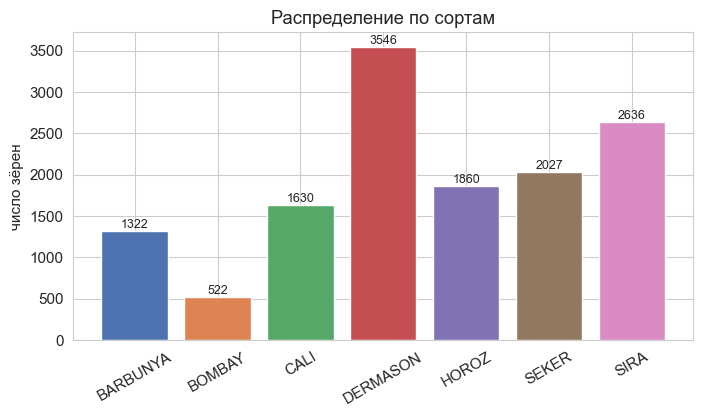

Средние признаков по сортам:


Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Area,6.98e+04,1.735e+05,7.554e+04,3.212e+04,5.367e+04,3.988e+04,4.473e+04
Perimeter,1046,1586,1058,665.2,920.1,727.7,796.4
MajorAxisLength,370,593.2,409.5,246.6,372.7,251.3,299.4
MinorAxisLength,240.3,374.4,236.4,165.7,184.2,201.9,190.8
AspectRation,1.544,1.586,1.734,1.49,2.027,1.245,1.57
Eccentricity,0.7547,0.7705,0.8148,0.7366,0.8675,0.5848,0.7673
ConvexArea,7.103e+04,1.758e+05,7.669e+04,3.25e+04,5.446e+04,4.027e+04,4.527e+04
EquivDiameter,297.3,468.9,309.5,201.7,260.8,224.9,238.3
Extent,0.7493,0.7766,0.759,0.753,0.7055,0.7717,0.7494
Solidity,0.9828,0.9869,0.985,0.9882,0.9855,0.9904,0.988


In [3]:
desc = df[FEATURES].describe().T
desc["skew"] = df[FEATURES].skew()
desc["kurtosis"] = df[FEATURES].kurtosis()
display(desc.round(4))

counts = df[TARGET].value_counts().reindex(CLASS_ORDER)
shares = pd.DataFrame({"n": counts, "доля": counts / counts.sum()})
display(shares.round(4))

chi, chi_p = chisquare(counts.to_numpy())
ratio = counts.max() / counts.min()
print(
    f"χ² против равных долей = {chi:.1f}, p = {fmt_p(chi_p)}. "
    f"Самый частый сорт {counts.idxmax()} ({int(counts.max())}), "
    f"самый редкий {counts.idxmin()} ({int(counts.min())}), отношение {ratio:.2f}."
)
if chi_p < 0.05:
    print("Доли сортов различаются. Разбиение будет стратифицированным, рядом с accuracy смотрим macro-F1.")
else:
    print("Равенство долей не отвергается. Macro-F1 всё равно считаем: сортов семь.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.to_numpy(), color=[PALETTE[c] for c in counts.index])
ax.set_ylabel("число зёрен")
ax.set_title("Распределение по сортам")
ax.tick_params(axis="x", labelrotation=30)
for i, value in enumerate(counts.to_numpy()):
    ax.text(i, value + 40, str(int(value)), ha="center", fontsize=9)
plt.show()

means = df.groupby(TARGET)[FEATURES].mean().reindex(CLASS_ORDER).T
means_fmt = means.map(lambda v: f"{v:.4g}")
print("Средние признаков по сортам:")
display(means_fmt)

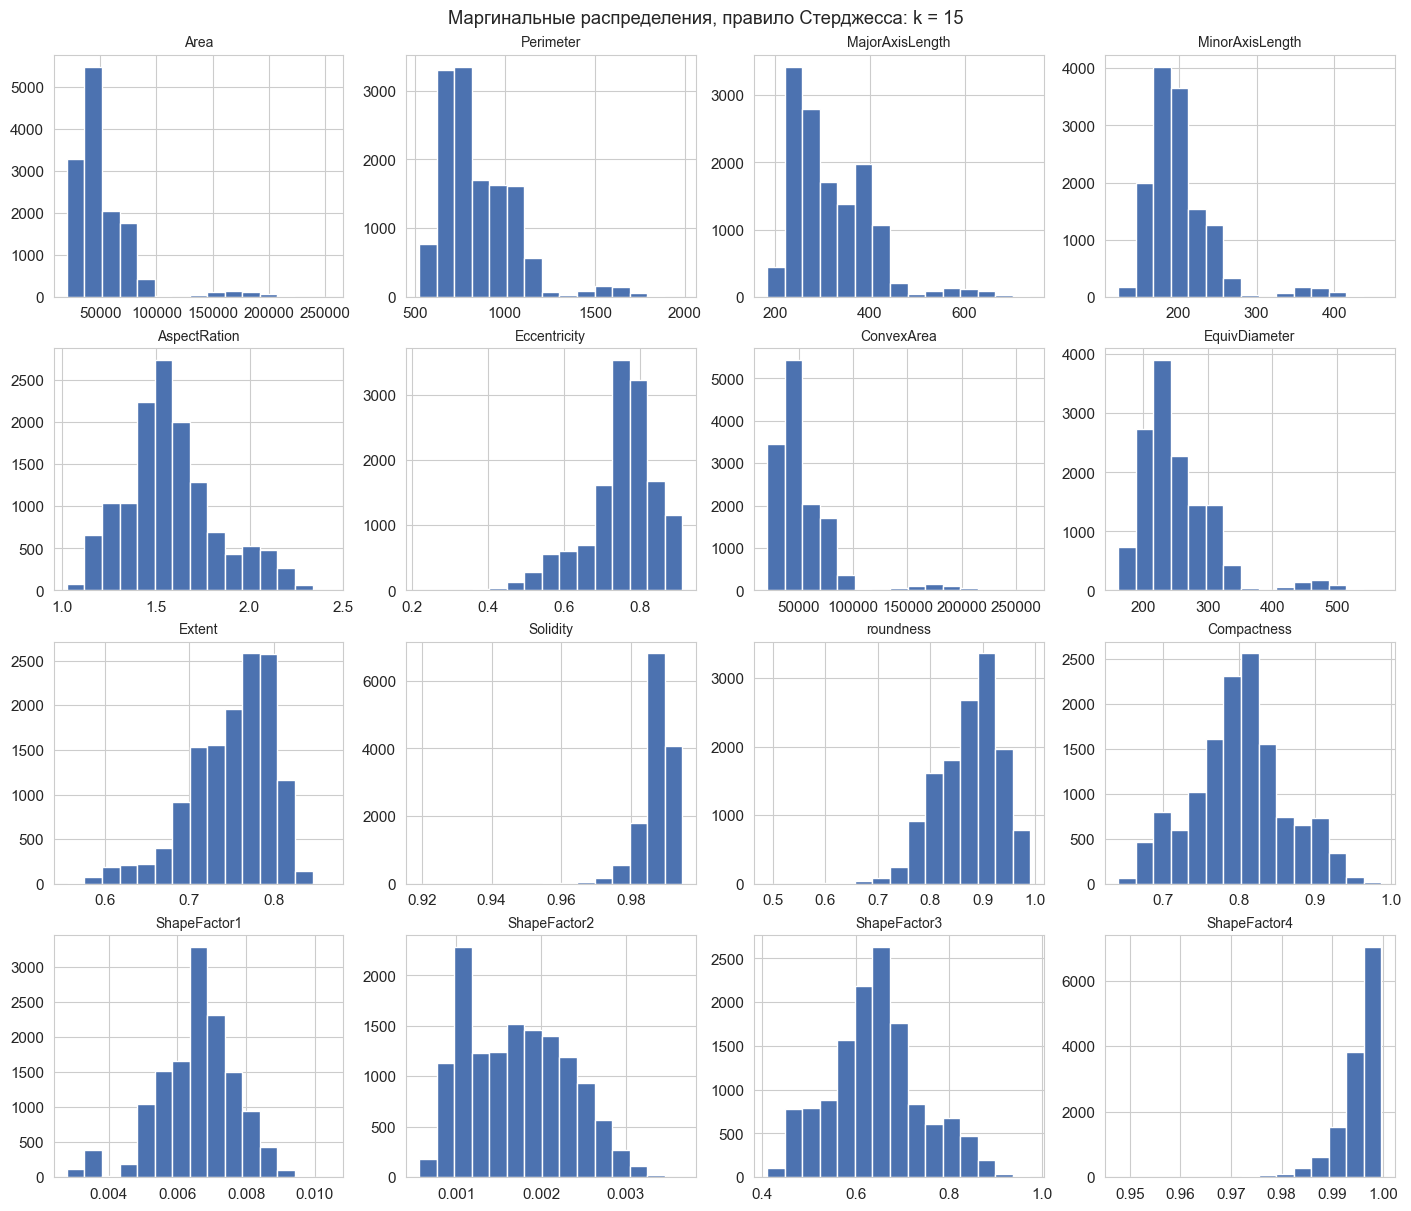

In [4]:
k_bins = int(np.ceil(np.log2(len(df)) + 1))
fig, axes = plt.subplots(4, 4, figsize=(14, 12), constrained_layout=True)
for ax, col in zip(axes.ravel(), FEATURES):
    ax.hist(df[col], bins=k_bins, color="#4C72B0", edgecolor="white")
    ax.set_title(col, fontsize=10)
fig.suptitle(f"Маргинальные распределения, правило Стерджесса: k = {k_bins}")
plt.show()

In [5]:
rows = []
for col in FEATURES:
    x = df[col].to_numpy()
    _, p_dag = normaltest(x)
    _, p_jb = jarque_bera(x)
    rows.append({
        "признак": col,
        "skew": df[col].skew(),
        "kurtosis": df[col].kurtosis(),
        "p_dagostino": p_dag,
        "p_jarque": p_jb,
    })
marg = pd.DataFrame(rows)
marg["практическое отклонение"] = (marg["skew"].abs() > 1) | (marg["kurtosis"].abs() > 2)

view = marg.copy()
for col in ("skew", "kurtosis"):
    view[col] = marg[col].map(lambda v: f"{v:.2f}")
view["p_dagostino"] = marg["p_dagostino"].map(fmt_p)
view["p_jarque"] = marg["p_jarque"].map(fmt_p)
view["практическое отклонение"] = marg["практическое отклонение"].map(lambda v: "да" if v else "нет")
display(view)

n_reject_marg = int(((marg["p_dagostino"] < 0.05) | (marg["p_jarque"] < 0.05)).sum())
n_practical = int(marg["практическое отклонение"].sum())
print(
    f"По всей выборке Д'Агостино или Харке–Бера отвергают нормальность у {n_reject_marg} из {len(FEATURES)} признаков "
    f"(α = 0.05). Правило практического отклонения: |асимметрия| > 1 или |эксцесс| > 2 — таких признаков {n_practical}."
)
print(
    "При n около 13 тысяч p-value реагирует и на мелкий уход от нормальной кривой. "
    "Для выбора метода важнее асимметрия и гистограммы, чем сам факт маленького p."
)

within_rows = []
for cls, part in df.groupby(TARGET):
    for col in FEATURES:
        x = part[col].to_numpy()
        try:
            _, p_value = shapiro(x)
        except Exception:
            p_value = np.nan
        within_rows.append({
            "сорт": cls,
            "признак": col,
            "n": len(part),
            "skew": float(pd.Series(x).skew()),
            "p_shapiro": p_value,
        })
within = pd.DataFrame(within_rows)
within["reject"] = within["p_shapiro"] < 0.05
summary = (
    within.groupby("признак")
    .apply(
        lambda g: pd.Series({
            "сортов с отказом": int(g["reject"].sum()),
            "медиана |skew|": float(g["skew"].abs().median()),
            "макс |skew|": float(g["skew"].abs().max()),
        }),
        include_groups=False,
    )
    .reindex(FEATURES)
)
display(summary.round(3))
n_pairs = len(within)
n_rej = int(within["reject"].sum())
hard = summary.index[summary["медиана |skew|"] > 1].tolist()
print(
    f"Внутри сортов Шапиро–Уилк, α = 0.05: отказ в {n_rej} из {n_pairs} пар признак×сорт. "
    f"Объём каждого сорта меньше 5000, для Шапиро–Уилка это рабочий диапазон."
)
if hard:
    print("Внутри сортов медианная |асимметрия| больше 1 у признаков:", ", ".join(hard))
else:
    print("Внутри сортов медианная |асимметрия| не превосходит 1 ни у одного признака.")
print(
    "Выбор методов. Сорт — номинальная метка из семи значений, решается задача классификации. "
    f"Отношение численностей {ratio:.2f}, поэтому разбиение стратифицируем и смотрим macro-F1 вместе с accuracy. "
    "Признаки непрерывные, пропусков нет. Размеры скошены: крупные зёрна вытягивают правый хвост площади и осей. "
    "Дерево решений строится без предпосылки нормальности и без общего масштаба признаков. "
    "Линейный дискриминантный анализ использует сдвиг средних и общую ковариацию. "
    f"Внутриклассовая нормальность выполняется не везде (отказов Шапиро–Уилка {n_rej} из {n_pairs}), "
    "поэтому LDA берём как линейный разделитель семи сортов. "
    "Объектов намного больше, чем признаков, общую ковариацию оценить можно. "
    "Эти две модели закрывают отчёт: у дерева в узлах виден индекс Джини, у LDA выписывается дискриминантная функция. "
    "Признаков 16, и многие из них — функции контура, так что разделяющая граница читается в размерах и форме."
)

,признак,skew,kurtosis,p_dagostino,p_jarque,практическое отклонение
0,Area,2.95,10.74,< 1e-300,< 1e-300,да
1,Perimeter,1.63,3.58,< 1e-300,< 1e-300,да
2,MajorAxisLength,1.37,2.54,< 1e-300,< 1e-300,да
3,MinorAxisLength,2.23,6.61,< 1e-300,< 1e-300,да
4,AspectRation,0.59,0.15,3.3566e-150,1.1411e-173,нет
5,Eccentricity,-1.06,1.40,< 1e-300,< 1e-300,да
6,ConvexArea,2.94,10.68,< 1e-300,< 1e-300,да
7,EquivDiameter,1.95,5.16,< 1e-300,< 1e-300,да
8,Extent,-0.90,0.65,< 1e-300,< 1e-300,нет
9,Solidity,-2.55,12.83,< 1e-300,< 1e-300,да


По всей выборке Д'Агостино или Харке–Бера отвергают нормальность у 16 из 16 признаков (α = 0.05). Правило практического отклонения: |асимметрия| > 1 или |эксцесс| > 2 — таких признаков 9.
При n около 13 тысяч p-value реагирует и на мелкий уход от нормальной кривой. Для выбора метода важнее асимметрия и гистограммы, чем сам факт маленького p.


,сортов с отказом,медиана |skew|,макс |skew|
признак,,,
Area,7.0,0.185,0.742
Perimeter,5.0,0.158,0.812
MajorAxisLength,5.0,0.097,0.770
MinorAxisLength,7.0,0.174,0.626
AspectRation,5.0,0.355,0.970
Eccentricity,7.0,0.893,1.519
ConvexArea,7.0,0.191,0.752
EquivDiameter,4.0,0.216,0.565
Extent,7.0,0.165,0.885


Внутри сортов Шапиро–Уилк, α = 0.05: отказ в 100 из 112 пар признак×сорт. Объём каждого сорта меньше 5000, для Шапиро–Уилка это рабочий диапазон.
Внутри сортов медианная |асимметрия| больше 1 у признаков: Solidity, roundness, ShapeFactor4
Выбор методов. Сорт — номинальная метка из семи значений, решается задача классификации. Отношение численностей 6.79, поэтому разбиение стратифицируем и смотрим macro-F1 вместе с accuracy. Признаки непрерывные, пропусков нет. Размеры скошены: крупные зёрна вытягивают правый хвост площади и осей. Дерево решений строится без предпосылки нормальности и без общего масштаба признаков. Линейный дискриминантный анализ использует сдвиг средних и общую ковариацию. Внутриклассовая нормальность выполняется не везде (отказов Шапиро–Уилка 100 из 112), поэтому LDA берём как линейный разделитель семи сортов. Объектов намного больше, чем признаков, общую ковариацию оценить можно. Эти две модели закрывают отчёт: у дерева в узлах виден индекс Джини, у LDA выписывается 

## 3. Информативные признаки

Ранг считаем двумя способами. ANOVA F измеряет, насколько средние сортов разъехались относительно внутригруппового разброса. Взаимная информация ловит и нелинейную связь и не требует нормальности. При таком объёме p-value ANOVA проваливается к нулю почти у всех признаков, поэтому порог 0.05 здесь не отбирает: отбор идёт по рангу и по правилу копий.

Правило копий, порог \(|r| \ge 0{,}995\): признак не входит в модель, если он практически повторяет уже взятый более информативный признак. Так в дискриминантную функцию не попадают два столбца одного и того же размера. Слабые, но не копирующие признаки пока оставляем: их вклад проверим по обученной модели в пункте 11.

,признак,F,p_anova,MI,ранг_F,ранг_MI,в модели
0,Perimeter,24327.0,< 1e-300,1.055,4,1,да
1,ConvexArea,28960.4,< 1e-300,1.038,2,2,да
2,Area,29014.8,< 1e-300,1.035,1,3,"нет, копия"
3,EquivDiameter,25488.2,< 1e-300,1.035,3,4,да
4,MajorAxisLength,21631.5,< 1e-300,0.993,6,5,да
5,ShapeFactor2,12203.8,< 1e-300,0.953,7,6,да
6,ShapeFactor1,12101.1,< 1e-300,0.929,8,7,да
7,MinorAxisLength,22431.9,< 1e-300,0.927,5,8,да
8,Compactness,9991.1,< 1e-300,0.831,10,9,да
9,ShapeFactor3,9734.7,< 1e-300,0.831,11,10,"нет, копия"


Согласованность рангов F и взаимной информации: Spearman ρ = 0.944, p = 3.9339e-08.
p-value ANOVA упирается в нижнюю границу float64: при семи сортах и n ≈ 13 тысячах средний сдвиг велик относительно ошибки среднего. Ранг читаем по F и по MI.
Порог копии |r| ≥ 0.995:
  Area повторяет ConvexArea, r = 0.9999, в модель не входит
  ShapeFactor3 повторяет Compactness, r = 0.9987, в модель не входит
Рабочий набор, 14 признаков: Perimeter, MajorAxisLength, MinorAxisLength, AspectRation, Eccentricity, ConvexArea, EquivDiameter, Extent, Solidity, roundness, Compactness, ShapeFactor1, ShapeFactor2, ShapeFactor4
Пять наиболее информативных по взаимной информации: Perimeter, ConvexArea, Area, EquivDiameter, MajorAxisLength


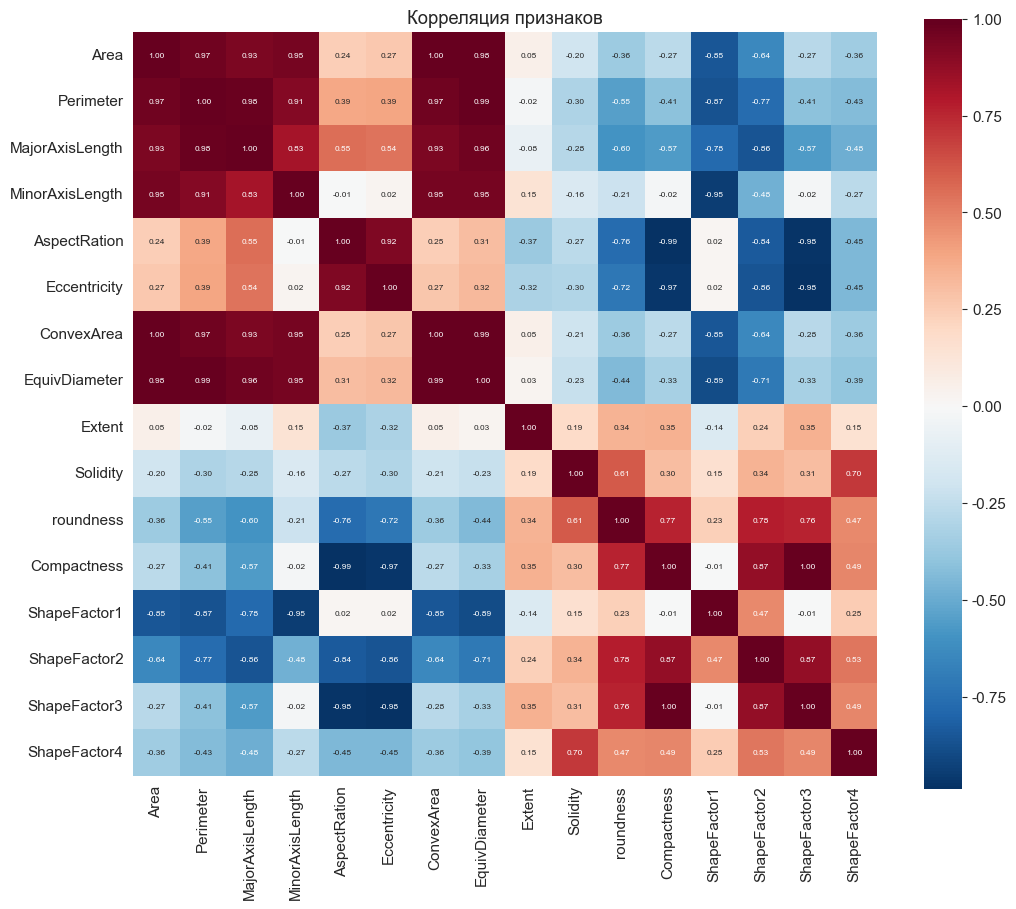

Пары с |r| ≥ 0.97:
  Area — ConvexArea: r = 1.000
  Compactness — ShapeFactor3: r = 0.999
  Perimeter — EquivDiameter: r = 0.991
  AspectRation — Compactness: r = -0.988
  ConvexArea — EquivDiameter: r = 0.985
  Area — EquivDiameter: r = 0.985
  Eccentricity — ShapeFactor3: r = -0.981
  AspectRation — ShapeFactor3: r = -0.979
  Perimeter — MajorAxisLength: r = 0.978
  Eccentricity — Compactness: r = -0.970
У таких пар один геометрический сигнал. Коэффициенты LDA у двух членов пары делят этот сигнал, читать их по отдельности нельзя. Дерево обычно ставит порог по одному признаку из пары.


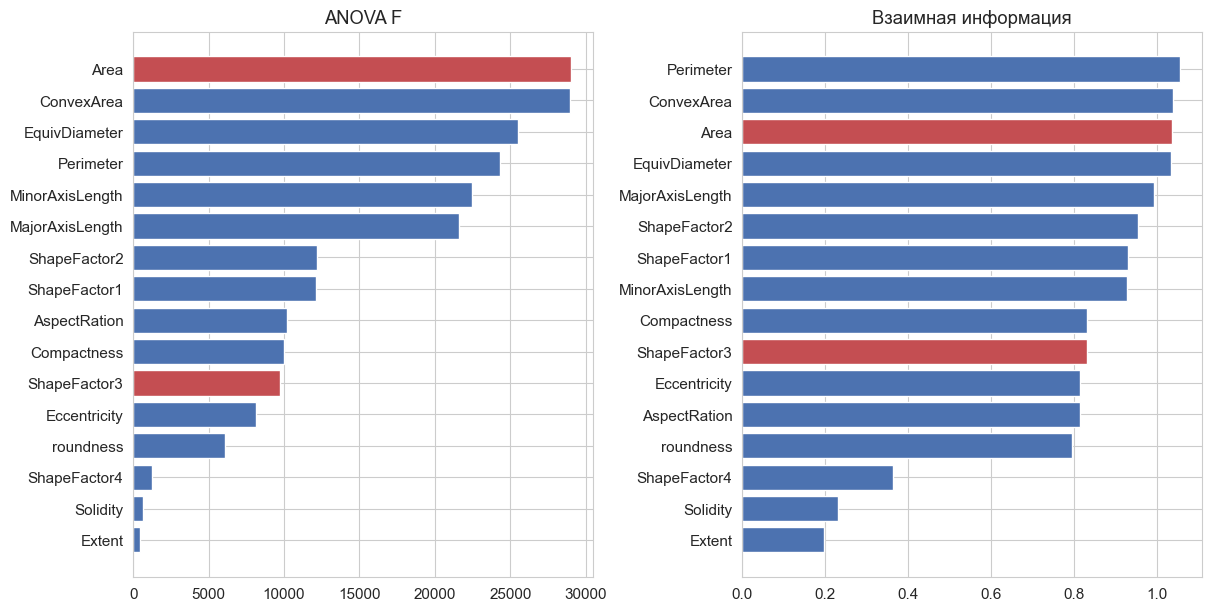

Красные столбцы — признаки-копии, в модель они не входят. Синие входят.


In [6]:
f_stat, f_p = f_classif(df[FEATURES], df[TARGET])
mi = mutual_info_classif(df[FEATURES], df[TARGET], random_state=42)
rank_tbl = pd.DataFrame({
    "признак": FEATURES,
    "F": f_stat,
    "p_anova": f_p,
    "MI": mi,
})
rank_tbl["ранг_F"] = rank_tbl["F"].rank(ascending=False, method="min").astype(int)
rank_tbl["ранг_MI"] = rank_tbl["MI"].rank(ascending=False, method="min").astype(int)
rho_rank, rho_p = spearmanr(rank_tbl["F"], rank_tbl["MI"])

corr = df[FEATURES].corr()
kept = []
dropped_copies = []
order_mi = rank_tbl.sort_values("MI", ascending=False, kind="mergesort")["признак"].tolist()
for feature in order_mi:
    copies = [other for other in kept if abs(corr.loc[feature, other]) >= COPY_R]
    if copies:
        partner = max(copies, key=lambda other: abs(corr.loc[feature, other]))
        dropped_copies.append((feature, partner, float(corr.loc[feature, partner])))
    else:
        kept.append(feature)
MODEL_FEATURES = [c for c in FEATURES if c in set(kept)]

rank_tbl["в модели"] = rank_tbl["признак"].map(lambda f: "да" if f in set(MODEL_FEATURES) else "нет, копия")
view = rank_tbl.sort_values("MI", ascending=False).copy()
view["F"] = rank_tbl.sort_values("MI", ascending=False)["F"].map(lambda v: f"{v:.1f}")
view["MI"] = rank_tbl.sort_values("MI", ascending=False)["MI"].map(lambda v: f"{v:.3f}")
view["p_anova"] = rank_tbl.sort_values("MI", ascending=False)["p_anova"].map(fmt_p)
display(view.reset_index(drop=True))
print(f"Согласованность рангов F и взаимной информации: Spearman ρ = {rho_rank:.3f}, p = {fmt_p(rho_p)}.")
print(
    "p-value ANOVA упирается в нижнюю границу float64: при семи сортах и n ≈ 13 тысячах "
    "средний сдвиг велик относительно ошибки среднего. Ранг читаем по F и по MI."
)
if dropped_copies:
    print(f"Порог копии |r| ≥ {COPY_R}:")
    for feature, partner, value in dropped_copies:
        print(f"  {feature} повторяет {partner}, r = {value:.4f}, в модель не входит")
else:
    print(f"Пар с |r| ≥ {COPY_R} нет, в модель входят все признаки.")
print(f"Рабочий набор, {len(MODEL_FEATURES)} признаков:", ", ".join(MODEL_FEATURES))
top_mi = rank_tbl.sort_values("MI", ascending=False)["признак"].head(5).tolist()
print("Пять наиболее информативных по взаимной информации:", ", ".join(top_mi))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr, ax=ax, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
    annot_kws={"size": 6}, square=True,
)
ax.set_title("Корреляция признаков")
plt.show()

high_pairs = []
for i, left in enumerate(FEATURES):
    for right in FEATURES[i + 1:]:
        value = float(corr.loc[left, right])
        if abs(value) >= 0.97:
            high_pairs.append((abs(value), left, right, value))
high_pairs.sort(reverse=True)
print("Пары с |r| ≥ 0.97:")
if high_pairs:
    for _, left, right, value in high_pairs:
        print(f"  {left} — {right}: r = {value:.3f}")
    print(
        "У таких пар один геометрический сигнал. Коэффициенты LDA у двух членов пары делят этот сигнал, "
        "читать их по отдельности нельзя. Дерево обычно ставит порог по одному признаку из пары."
    )
else:
    print("  нет")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, col, title in ((axes[0], "F", "ANOVA F"), (axes[1], "MI", "Взаимная информация")):
    ordered = rank_tbl.sort_values(col)
    colors = ["#4C72B0" if f in set(MODEL_FEATURES) else "#C44E52" for f in ordered["признак"]]
    ax.barh(ordered["признак"], ordered[col], color=colors)
    ax.set_title(title)
plt.show()
if dropped_copies:
    print("Красные столбцы — признаки-копии, в модель они не входят. Синие входят.")

## 4. Стандартизация

Площадь измеряется десятками тысяч пикселей, эксцентриситет лежит между 0 и 1, форм-факторы — порядка \(10^{-3}\). Дерево сравнивает один признак с порогом: монотонный масштаб не меняет состав ветвей, пороги оставляем в исходных единицах, чтобы они читались как пиксели и отношения.

LDA инвариантен к невырожденному линейному преобразованию признаков, поэтому стандартизация не меняет назначенный сорт. Её делаем, чтобы коэффициент был вкладом одного обучающего стандартного отклонения и коэффициенты разных признаков можно было сравнивать. Среднее и дисперсию считаем только по обучающей части, уже после разбиения: тестовые строки в эти оценки не входят.

In [7]:
scale_tbl = pd.DataFrame({
    "mean": df[FEATURES].mean(),
    "std": df[FEATURES].std(),
    "min": df[FEATURES].min(),
    "max": df[FEATURES].max(),
})
scale_tbl["range"] = scale_tbl["max"] - scale_tbl["min"]
scale_tbl = scale_tbl.sort_values("std")
display(scale_tbl.map(lambda v: f"{v:.4g}"))
std_ratio = scale_tbl["std"].iloc[-1] / scale_tbl["std"].iloc[0]
print(
    f"Стандартное отклонение: минимум у {scale_tbl.index[0]} ({scale_tbl['std'].iloc[0]:.4g}), "
    f"максимум у {scale_tbl.index[-1]} ({scale_tbl['std'].iloc[-1]:.4g}), отношение {std_ratio:.0f} раз."
)
print(
    "Дерево учится на исходной матрице. В LDA перед дискриминантной функцией стоит StandardScaler, "
    "он будет обучен на train в пункте 7."
)

,mean,std,min,max,range
ShapeFactor2,0.001719,0.0005955,0.0005642,0.003665,0.003101
ShapeFactor1,0.006561,0.00113,0.002778,0.01045,0.007673
ShapeFactor4,0.9951,0.004347,0.9477,0.9997,0.05205
Solidity,0.9872,0.00465,0.9192,0.9947,0.07543
Extent,0.7498,0.04894,0.5553,0.8662,0.3109
roundness,0.8737,0.05939,0.4896,0.9907,0.5011
Compactness,0.8004,0.06146,0.6406,0.9873,0.3467
Eccentricity,0.7503,0.09186,0.219,0.9114,0.6925
ShapeFactor3,0.6443,0.09865,0.4103,0.9748,0.5644
AspectRation,1.581,0.2452,1.025,2.43,1.405


Стандартное отклонение: минимум у ShapeFactor2 (0.0005955), максимум у ConvexArea (2.984e+04), отношение 50118502 раз.
Дерево учится на исходной матрице. В LDA перед дискриминантной функцией стоит StandardScaler, он будет обучен на train в пункте 7.


## 5. Диаграммы рассеяния и расположение классов

Тепловая карта — средние сортов в долях общего стандартного отклонения: положительное значение значит, что сорт крупнее или «более вытянут», чем выборка в целом. Ящики — все зёрна. Точки на рассеянии — по 300 зёрен каждого сорта, иначе частый сорт закрасит редкий. В обучение и тест идут все строки после удаления дубликатов, подвыборка нужна только рисунку.

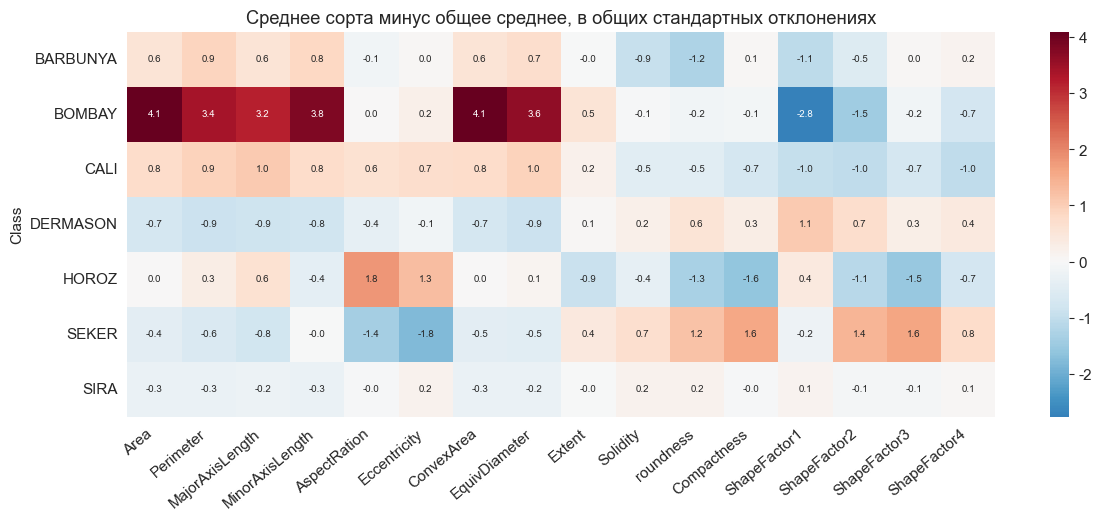

BARBUNYA: выше среднего по Perimeter (+0.89 σ), ниже по roundness (-1.24 σ).
BOMBAY: выше среднего по Area (+4.10 σ), ниже по ShapeFactor1 (-2.76 σ).
CALI: выше среднего по MajorAxisLength (+1.04 σ), ниже по ShapeFactor4 (-1.03 σ).
DERMASON: выше среднего по ShapeFactor1 (+1.06 σ), ниже по Perimeter (-0.88 σ).
HOROZ: выше среднего по AspectRation (+1.82 σ), ниже по Compactness (-1.62 σ).
SEKER: выше среднего по ShapeFactor3 (+1.63 σ), ниже по Eccentricity (-1.80 σ).
SIRA: выше среднего по roundness (+0.18 σ), ниже по ConvexArea (-0.28 σ).


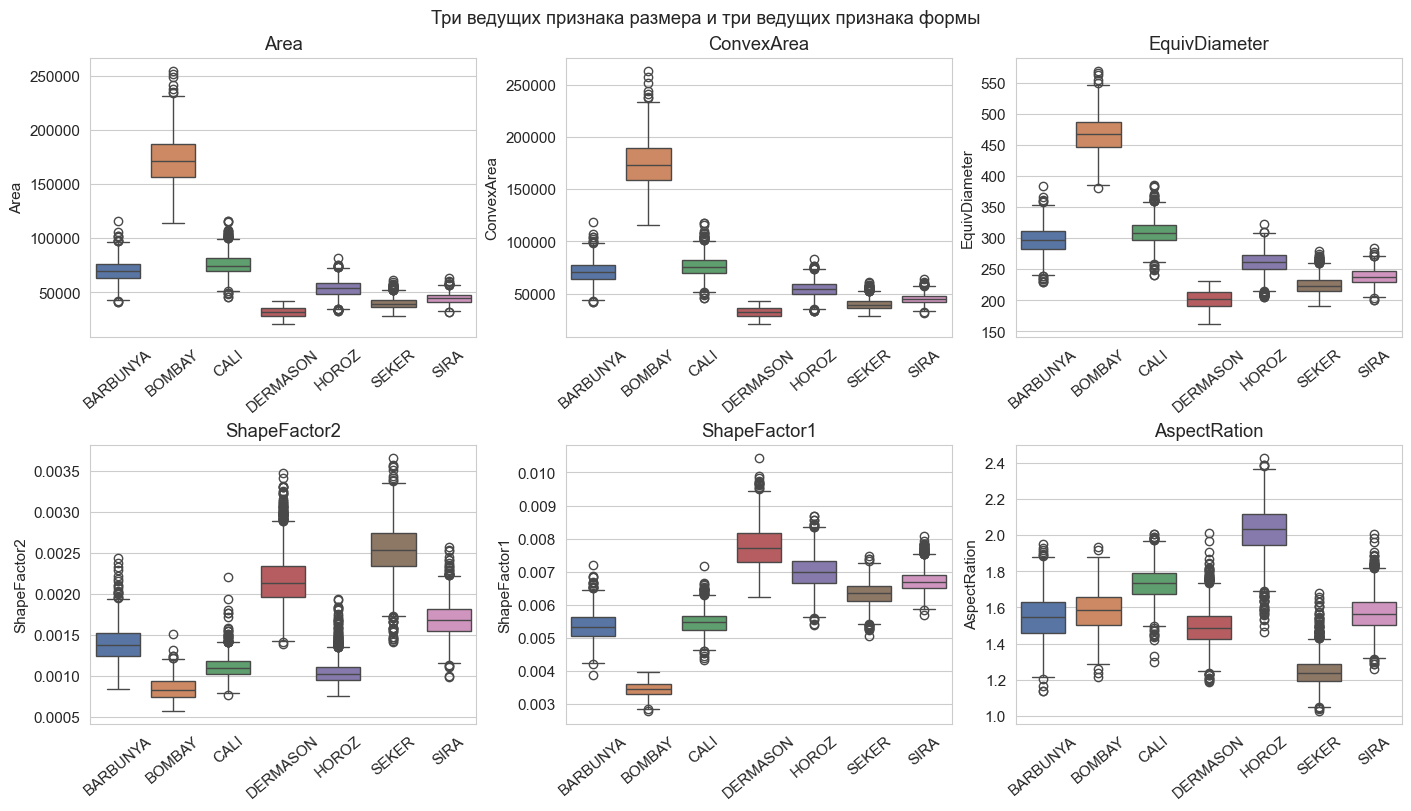

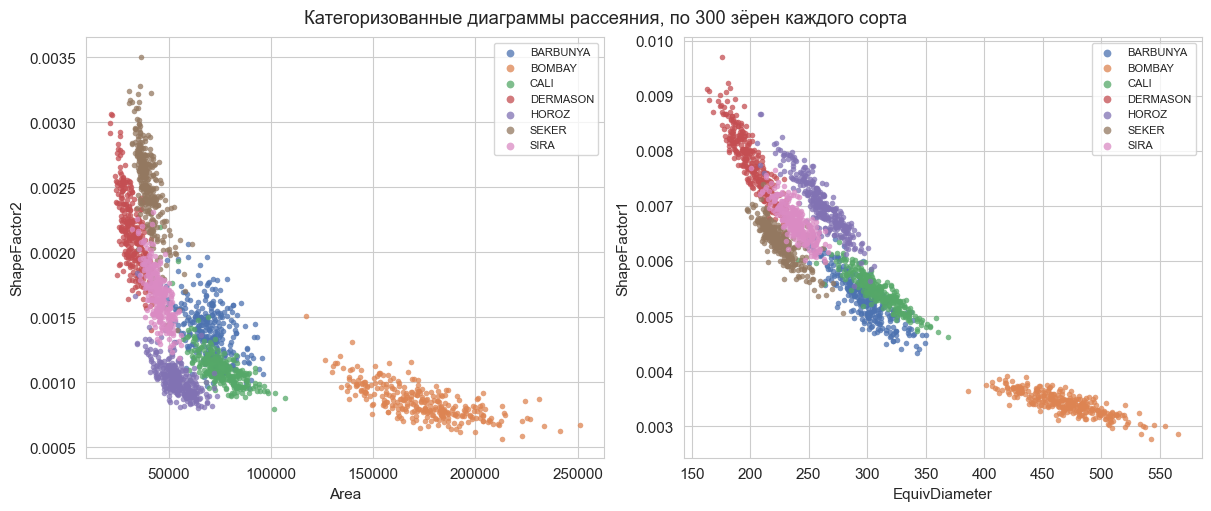

Крупный сорт стоит отдельно по площади и осям. Вытянутые и округлые сорта расходятся по отношению осей, компактности и форм-факторам. Близкие по размеру сорта накрывают друг друга: одной прямой по площади их не разделить, нужны и размер, и форма. Это видно и по ящикам, и по точкам.


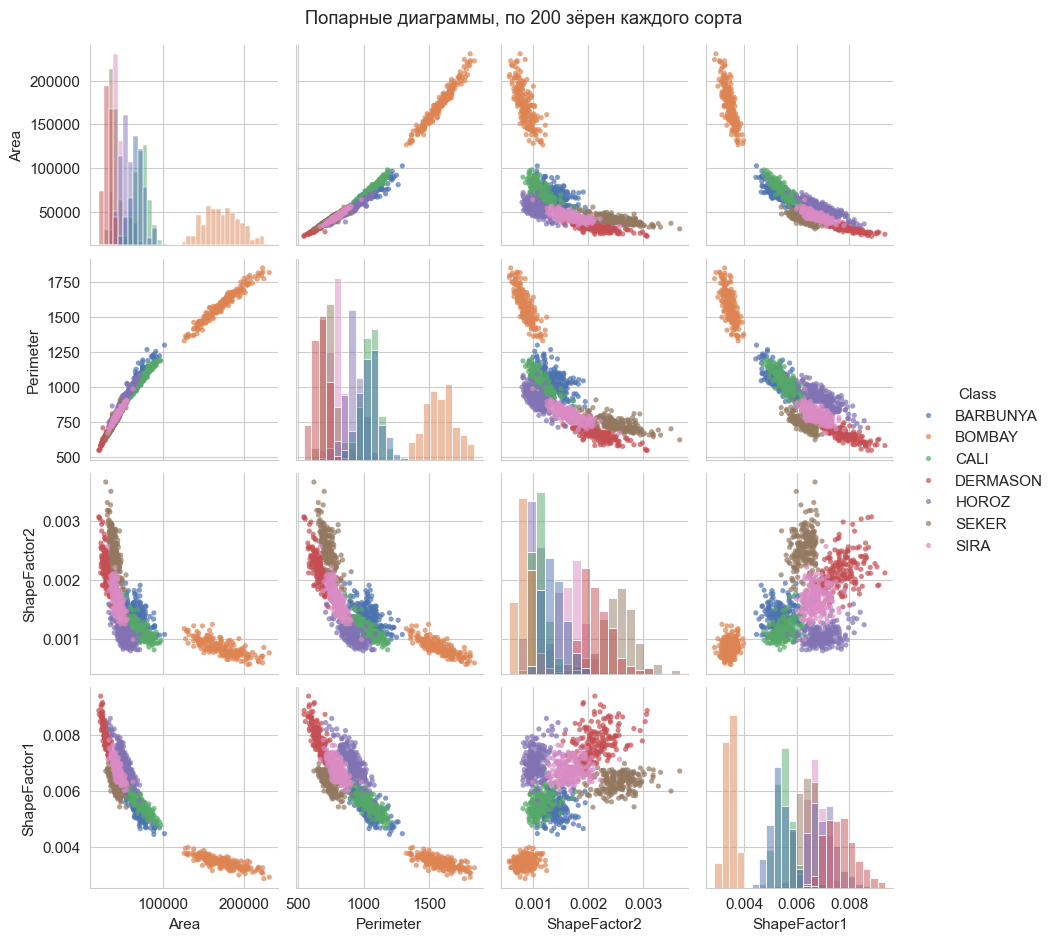

In [8]:
center = df[FEATURES].mean()
spread = df[FEATURES].std(ddof=1)
zmeans = (df.groupby(TARGET)[FEATURES].mean() - center) / spread
zmeans = zmeans.reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(zmeans, ax=ax, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Среднее сорта минус общее среднее, в общих стандартных отклонениях")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.show()
for cls, row in zmeans.iterrows():
    hi = row.idxmax()
    lo = row.idxmin()
    print(f"{cls}: выше среднего по {hi} ({row[hi]:+.2f} σ), ниже по {lo} ({row[lo]:+.2f} σ).")

size_ranked = [f for f in rank_tbl.sort_values("F", ascending=False)["признак"] if f in SIZE_FEATURES]
shape_ranked = [f for f in rank_tbl.sort_values("F", ascending=False)["признак"] if f not in SIZE_FEATURES]
show_cols = size_ranked[:3] + shape_ranked[:3]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for ax, col in zip(axes.ravel(), show_cols):
    sns.boxplot(
        data=df, x=TARGET, y=col, hue=TARGET,
        order=CLASS_ORDER, hue_order=CLASS_ORDER,
        palette=PALETTE, legend=False, ax=ax,
    )
    ax.set_xlabel("")
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=40)
fig.suptitle("Три ведущих признака размера и три ведущих признака формы")
plt.show()


def stratified_sample(frame, n_per_class, seed=42):
    rng = np.random.default_rng(seed)
    parts = []
    for cls in CLASS_ORDER:
        part = frame[frame[TARGET] == cls]
        take = min(n_per_class, len(part))
        idx = rng.choice(part.index.to_numpy(), size=take, replace=False)
        parts.append(frame.loc[idx])
    return pd.concat(parts, axis=0)


def class_scatter(ax, frame, xname, yname):
    for cls in CLASS_ORDER:
        mask = frame[TARGET] == cls
        ax.scatter(
            frame.loc[mask, xname], frame.loc[mask, yname],
            s=16, alpha=0.75, c=PALETTE[cls], label=cls, linewidths=0,
        )
    ax.set_xlabel(xname)
    ax.set_ylabel(yname)
    ax.legend(fontsize=8, markerscale=1.4, frameon=True)


scatter_df = stratified_sample(df, 300, seed=42)
x1, y1 = size_ranked[0], shape_ranked[0]
x2 = size_ranked[min(2, len(size_ranked) - 1)]
y2 = shape_ranked[min(1, len(shape_ranked) - 1)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
class_scatter(axes[0], scatter_df, x1, y1)
class_scatter(axes[1], scatter_df, x2, y2)
fig.suptitle("Категоризованные диаграммы рассеяния, по 300 зёрен каждого сорта")
plt.show()
print(
    "Крупный сорт стоит отдельно по площади и осям. Вытянутые и округлые сорта расходятся по отношению осей, "
    "компактности и форм-факторам. Близкие по размеру сорта накрывают друг друга: одной прямой по площади их не разделить, "
    "нужны и размер, и форма. Это видно и по ящикам, и по точкам."
)

candidates = [
    size_ranked[0],
    size_ranked[min(3, len(size_ranked) - 1)],
    shape_ranked[0],
    shape_ranked[1],
    shape_ranked[min(2, len(shape_ranked) - 1)],
]
pair_cols = []
for feature in candidates:
    if feature not in pair_cols:
        pair_cols.append(feature)
    if len(pair_cols) == 4:
        break
pair_df = stratified_sample(df[pair_cols + [TARGET]], 200, seed=42)
g = sns.pairplot(
    pair_df, vars=pair_cols, hue=TARGET, hue_order=CLASS_ORDER, palette=PALETTE,
    diag_kind="hist", height=2.3,
    plot_kws={"alpha": 0.7, "s": 14, "linewidth": 0},
)
g.fig.suptitle("Попарные диаграммы, по 200 зёрен каждого сорта", y=1.02)
plt.show()

## 6. Обучающая и тестовая выборки

Доля теста 30%, разбиение стратифицированное, `random_state = 42`. При 13 тысячах зёрен в тесте остаётся несколько тысяч объектов и больше сотни зёрен даже у самого редкого сорта, так что полнота по сорту оценивается устойчиво. В обучение попадает около 70% — этого достаточно для общей ковариации LDA при 14 признаках и для дерева с листом из 20 объектов.

In [9]:
X_model = df[MODEL_FEATURES]
y_model = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.30, random_state=42, stratify=y_model,
)
split_counts = pd.DataFrame({
    "обучение": y_train.value_counts().reindex(CLASS_ORDER),
    "тест": y_test.value_counts().reindex(CLASS_ORDER),
})
split_share = pd.DataFrame({
    "доля обучения": y_train.value_counts(normalize=True).reindex(CLASS_ORDER),
    "доля теста": y_test.value_counts(normalize=True).reindex(CLASS_ORDER),
})
print(f"Обучение: {len(y_train)}, тест: {len(y_test)} ({len(y_test) / len(y_model):.0%}).")
display(split_counts.astype(int))
display(split_share.round(3))
print(
    f"Минимальный сорт в тесте: {int(split_counts['тест'].min())} зёрен ({split_counts['тест'].idxmin()}). "
    "Доли в двух частях близки: сработала стратификация."
)

Обучение: 9480, тест: 4063 (30%).


,обучение,тест
Class,,
BARBUNYA,925,397
BOMBAY,366,156
CALI,1141,489
DERMASON,2482,1064
HOROZ,1302,558
SEKER,1419,608
SIRA,1845,791


,доля обучения,доля теста
Class,,
BARBUNYA,0.098,0.098
BOMBAY,0.039,0.038
CALI,0.120,0.120
DERMASON,0.262,0.262
HOROZ,0.137,0.137
SEKER,0.150,0.150
SIRA,0.195,0.195


Минимальный сорт в тесте: 156 зёрен (BOMBAY). Доли в двух частях близки: сработала стратификация.


## 7. Модели

Две модели: дерево решений и линейный дискриминантный анализ.

Индекс Джини в узле

\[
G = 1 - \sum_k p_k^2,
\]

где \(p_k\) — доля сорта \(k\) в узле. На каждом шаге выбирается признак и порог с наибольшим убыванием \(G\), веса — размеры дочерних узлов. В лист объект попадает после серии таких порогов. Прогноз листа — сорт с наибольшей долей.

Дискриминантная функция сорта \(k\) на стандартизованных признаках обучающей выборки

\[
d_k(z) = \beta_{k0} + \sum_j \beta_{kj} z_j, \quad z_j = (x_j - \bar x_j) / s_j.
\]

Сорт объекта — \(\arg\max_k d_k(z)\). Средние \(\bar x_j\) и стандартные отклонения \(s_j\) считаются по обучению. Знак канонической оси LD условный: смена знака всех коэффициентов одной оси отражает картинку и сохраняет разделение.

Параметры заданы до просмотра тестовой ошибки.

- Дерево: `criterion=gini`, `max_depth=8`, `min_samples_leaf=20`, `min_samples_split=40`, `random_state=42`. Семи сортам нужны последовательные пороги и по размеру, и по форме; глубины 3 хватает только на грубые группы. Глубина 8 оставляет запас для формы внутри размерной группы. Лист из 20 зёрен при обучении около 9 тысяч объектов — ещё группа, а не одно зерно. Порог ветвления вдвое больше листа, чтобы оба потомка могли набрать 20 объектов. Джини нужен в узлах отчёта и учитывает неравные доли сортов.
- LDA: `solver=svd`, априорные вероятности — доли сортов в обучении, перед ним `StandardScaler` только по train. Признаков на порядок меньше, чем объектов минус число сортов, усадка ковариации не нужна. Внешних частот сортов нет, а в выборке доли различаются в разы, поэтому priors берём из обучения.

Максимум |среднее scaler − среднее train| = 0.00e+00.
Тот же максимум против среднего всей выборки = 61.24.
Средние scaler совпадают с обучением. Тестовые строки в оценки масштаба не входили.
Общая ковариация LDA: матрица 14×14.
Обучение 9480, признаков 14, сортов 7. Степеней свободы внутри сортов около 9473, это больше числа признаков.
Априорные вероятности (доли обучения):
BARBUNYA    0.098
BOMBAY      0.039
CALI        0.120
DERMASON    0.262
HOROZ       0.137
SEKER       0.150
SIRA        0.195
Коэффициенты дискриминантных функций в стандартизованных признаках:


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Perimeter,44.541,-151.787,-70.865,32.432,-27.411,41.672,-4.731
MajorAxisLength,-200.697,-549.254,-31.192,213.095,-146.377,19.372,30.599
MinorAxisLength,-162.709,-290.794,19.784,136.149,-12.653,-94.611,25.565
AspectRation,15.949,83.250,-27.308,-44.478,72.210,24.091,-17.276
Eccentricity,0.256,12.791,-1.701,0.476,12.035,-9.179,-3.688
ConvexArea,-52.550,29.197,-72.407,11.584,10.859,23.514,24.001
EquivDiameter,387.104,1046.472,185.381,-382.321,139.561,-3.925,-97.462
Extent,0.452,0.481,0.507,-0.171,-0.263,-0.192,-0.073
Solidity,-1.785,-1.488,-1.115,0.166,1.594,-0.121,0.625
roundness,0.463,-20.372,-9.720,6.021,-5.607,8.160,-0.598


d[BARBUNYA] = -14.159 + 44.541·z(Perimeter) − 200.697·z(MajorAxisLength) − 162.709·z(MinorAxisLength) + 15.949·z(AspectRation) + 0.256·z(Eccentricity) − 52.550·z(ConvexArea) + 387.104·z(EquivDiameter) + 0.452·z(Extent) − 1.785·z(Solidity) + 0.463·z(roundness) + 27.348·z(Compactness) + 18.623·z(ShapeFactor1) + 1.575·z(ShapeFactor2) − 1.667·z(ShapeFactor4)
d[BOMBAY] = -178.255 − 151.787·z(Perimeter) − 549.254·z(MajorAxisLength) − 290.794·z(MinorAxisLength) + 83.250·z(AspectRation) + 12.791·z(Eccentricity) + 29.197·z(ConvexArea) + 1046.472·z(EquivDiameter) + 0.481·z(Extent) − 1.488·z(Solidity) − 20.372·z(roundness) + 17.478·z(Compactness) + 41.946·z(ShapeFactor1) + 67.289·z(ShapeFactor2) − 7.894·z(ShapeFactor4)
d[CALI] = -13.499 − 70.865·z(Perimeter) − 31.192·z(MajorAxisLength) + 19.784·z(MinorAxisLength) − 27.308·z(AspectRation) − 1.701·z(Eccentricity) − 72.407·z(ConvexArea) + 185.381·z(EquivDiameter) + 0.507·z(Extent) − 1.115·z(Solidity) − 9.720·z(roundness) − 79.581·z(Compactness) + 3.

,LD1,LD2
Perimeter,9.177,-6.086
MajorAxisLength,34.924,-19.466
MinorAxisLength,17.283,1.521
AspectRation,-4.484,5.756
Eccentricity,-0.720,1.273
ConvexArea,2.450,-5.383
EquivDiameter,-68.335,25.053
Extent,-0.049,0.010
Solidity,0.123,0.131
roundness,1.433,-1.330


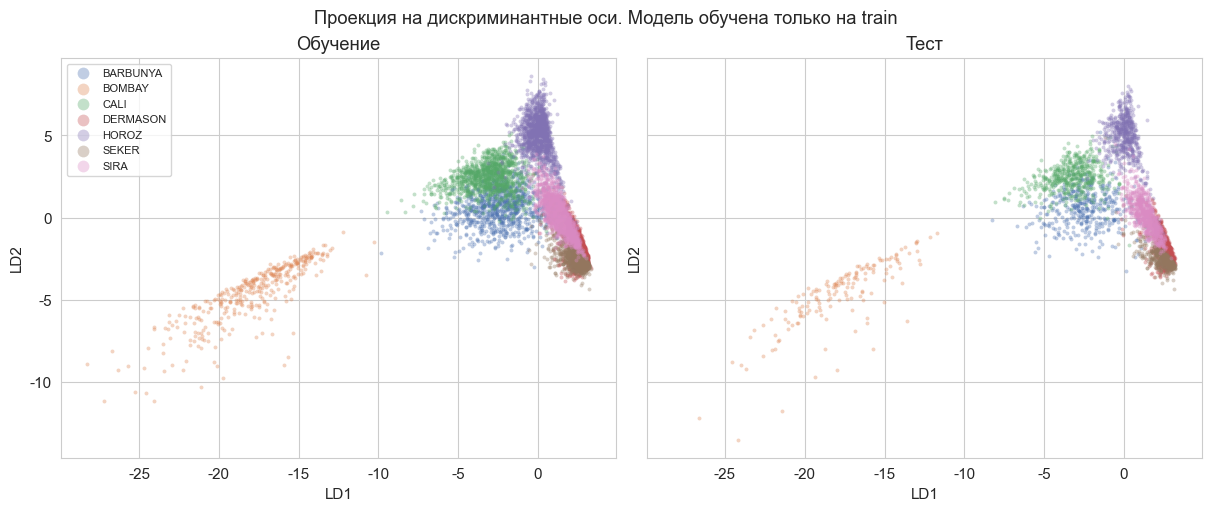

Корень дерева: Gini = 0.827, ветвление MajorAxisLength ≤ 281.847, объектов 9480.


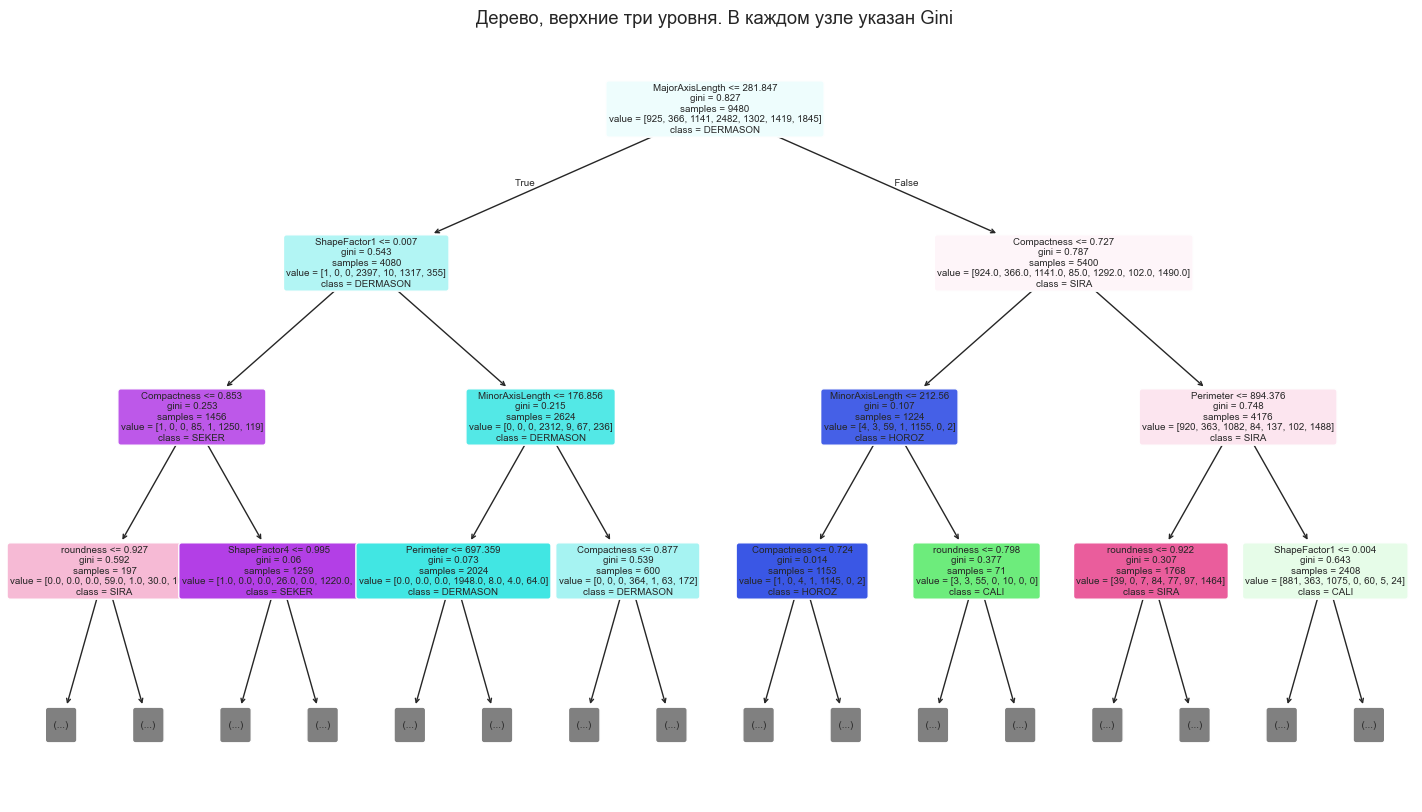

Правила тех же трёх уровней:
|--- MajorAxisLength <= 281.85
|   |--- ShapeFactor1 <= 0.01
|   |   |--- Compactness <= 0.85
|   |   |   |--- roundness <= 0.93
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- roundness >  0.93
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Compactness >  0.85
|   |   |   |--- ShapeFactor4 <= 1.00
|   |   |   |   |--- weights: [1.00, 0.00, 0.00, 6.00, 0.00, 14.00, 6.00] class: SEKER
|   |   |   |--- ShapeFactor4 >  1.00
|   |   |   |   |--- truncated branch of depth 5
|   |--- ShapeFactor1 >  0.01
|   |   |--- MinorAxisLength <= 176.86
|   |   |   |--- Perimeter <= 697.36
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- Perimeter >  697.36
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- MinorAxisLength >  176.86
|   |   |   |--- Compactness <= 0.88
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- Compactness >  0.88
|   |   |   |   |--- truncated branch of depth 2
|--- MajorAx

,узел,глубина,тип,правило,gini,объекты,сорт
0,0,0,ветвление,MajorAxisLength ≤ 281.847,0.827,9480,DERMASON
1,1,1,ветвление,ShapeFactor1 ≤ 0.007,0.543,4080,DERMASON
2,2,2,ветвление,Compactness ≤ 0.853,0.253,1456,SEKER
3,3,3,ветвление,roundness ≤ 0.927,0.592,197,SIRA
4,4,4,ветвление,Perimeter ≤ 745.911,0.481,148,SIRA
5,5,5,ветвление,ShapeFactor2 ≤ 0.002,0.545,40,DERMASON
6,6,6,лист,лист,0.455,20,DERMASON
7,7,6,лист,лист,0.565,20,SIRA
8,8,5,ветвление,Solidity ≤ 0.990,0.396,108,SIRA
9,9,6,ветвление,AspectRation ≤ 1.406,0.313,88,SIRA


Узлов 183, листьев 92, чистых листьев (Gini = 0) 15. Медианный Gini листа 0.263. Рисунок показывает три верхних уровня, таблица — Gini каждого узла, включая глубокие.


In [10]:
def make_tree(max_depth=TREE_DEPTH, min_samples_leaf=TREE_LEAF, criterion=TREE_CRITERION):
    return DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        min_samples_split=max(2, int(min_samples_leaf) * 2),
        random_state=42,
    )


def make_lda():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis(solver="svd", store_covariance=True)),
    ])


tree_clf = make_tree()
tree_clf.fit(X_train, y_train)
lda_pipe = make_lda()
lda_pipe.fit(X_train, y_train)

scaler = lda_pipe.named_steps["scaler"]
lda = lda_pipe.named_steps["lda"]
delta_train = float(np.max(np.abs(scaler.mean_ - X_train.mean().to_numpy())))
delta_all = float(np.max(np.abs(scaler.mean_ - X_model.mean().to_numpy())))
print(f"Максимум |среднее scaler − среднее train| = {delta_train:.2e}.")
print(f"Тот же максимум против среднего всей выборки = {delta_all:.4g}.")
print("Средние scaler совпадают с обучением. Тестовые строки в оценки масштаба не входили.")
print(f"Общая ковариация LDA: матрица {lda.covariance_.shape[0]}×{lda.covariance_.shape[1]}.")
df_within = len(X_train) - y_train.nunique()
print(
    f"Обучение {len(X_train)}, признаков {X_train.shape[1]}, сортов {y_train.nunique()}. "
    f"Степеней свободы внутри сортов около {df_within}, это больше числа признаков."
)
print("Априорные вероятности (доли обучения):")
print(pd.Series(lda.priors_, index=lda.classes_).round(3).to_string())

coef_tbl = pd.DataFrame(lda.coef_, index=list(lda.classes_), columns=list(X_train.columns)).T
coef_tbl.loc["свободный член"] = lda.intercept_
print("Коэффициенты дискриминантных функций в стандартизованных признаках:")
display(coef_tbl.round(3))
for class_name, coef_row, intercept in zip(lda.classes_, lda.coef_, lda.intercept_):
    parts = [f"{intercept:.3f}"]
    for feature, coef in zip(X_train.columns, coef_row):
        sign = "+" if coef >= 0 else "−"
        parts.append(f" {sign} {abs(coef):.3f}·z({feature})")
    print(f"d[{class_name}] = " + "".join(parts))
print("z(x) = (x − среднее_train) / std_train. Сорт = argmax d[k].")
for class_name, coef_row in zip(lda.classes_, lda.coef_):
    series = pd.Series(coef_row, index=X_train.columns).sort_values()
    low = ", ".join(f"{name} ({value:+.2f})" for name, value in series.head(3).items())
    high = ", ".join(f"{name} ({value:+.2f})" for name, value in series.tail(3).items())
    print(f"{class_name}: повышают счёт {high}; понижают {low}.")

var_share = lda.explained_variance_ratio_
print("Доли разделимой дисперсии:", ", ".join(f"LD{i + 1}={v:.3f}" for i, v in enumerate(var_share)))
n_show = min(2, lda.scalings_.shape[1])
scalings = pd.DataFrame(
    lda.scalings_[:, :n_show],
    index=X_train.columns,
    columns=[f"LD{i + 1}" for i in range(n_show)],
)
display(scalings.round(3))

proj_train = lda_pipe.transform(X_train)
proj_test = lda_pipe.transform(X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True)
for ax, proj, yy, title in (
    (axes[0], proj_train, y_train, "Обучение"),
    (axes[1], proj_test, y_test, "Тест"),
):
    y_arr = yy.to_numpy()
    for cls in CLASS_ORDER:
        mask = y_arr == cls
        ax.scatter(proj[mask, 0], proj[mask, 1], s=8, alpha=0.35, c=PALETTE[cls], label=cls, linewidths=0)
    ax.set_xlabel("LD1")
    ax.set_ylabel("LD2")
    ax.set_title(title)
axes[0].legend(fontsize=8, markerscale=3, frameon=True)
fig.suptitle("Проекция на дискриминантные оси. Модель обучена только на train")
plt.show()

root = tree_clf.tree_
root_name = X_train.columns[root.feature[0]]
print(
    f"Корень дерева: Gini = {root.impurity[0]:.3f}, "
    f"ветвление {root_name} ≤ {root.threshold[0]:.3f}, объектов {int(root.n_node_samples[0])}."
)
fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    tree_clf,
    feature_names=list(X_train.columns),
    class_names=list(tree_clf.classes_),
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    max_depth=3,
    fontsize=7,
    ax=ax,
)
ax.set_title("Дерево, верхние три уровня. В каждом узле указан Gini")
plt.show()
print("Правила тех же трёх уровней:")
print(export_text(
    tree_clf,
    feature_names=list(tree_clf.feature_names_in_),
    max_depth=3,
    decimals=2,
    show_weights=True,
))


def tree_nodes(clf):
    tree = clf.tree_
    names = list(clf.feature_names_in_)
    rows = []

    def walk(node, depth):
        is_leaf = tree.feature[node] < 0
        counts = tree.value[node][0]
        pred = clf.classes_[int(np.argmax(counts))]
        if is_leaf:
            rule = "лист"
        else:
            rule = f"{names[tree.feature[node]]} ≤ {tree.threshold[node]:.3f}"
        rows.append({
            "узел": node,
            "глубина": depth,
            "тип": "лист" if is_leaf else "ветвление",
            "правило": rule,
            "gini": tree.impurity[node],
            "объекты": int(tree.n_node_samples[node]),
            "сорт": pred,
        })
        if not is_leaf:
            walk(tree.children_left[node], depth + 1)
            walk(tree.children_right[node], depth + 1)

    walk(0, 0)
    return pd.DataFrame(rows)


nodes = tree_nodes(tree_clf)
nodes_view = nodes.copy()
nodes_view["gini"] = nodes["gini"].round(3)
display(nodes_view)
leaves = nodes[nodes["тип"] == "лист"]
n_pure = int((leaves["gini"] <= 1e-12).sum())
print(
    f"Узлов {len(nodes)}, листьев {len(leaves)}, чистых листьев (Gini = 0) {n_pure}. "
    f"Медианный Gini листа {leaves['gini'].median():.3f}. "
    "Рисунок показывает три верхних уровня, таблица — Gini каждого узла, включая глубокие."
)

## 8. Качество

Для семи сортов и одного ответа на зерно:

- accuracy — доля верных сортов;
- precision сорта — доля верных среди тех, кому назначен этот сорт;
- recall сорта — доля найденных зёрен этого сорта;
- F1 — гармоническое среднее precision и recall;
- macro — среднее по семи сортам, редкий сорт весит столько же, сколько частый;
- micro — общий пул верных и неверных срабатываний. В однометочной задаче micro-precision, micro-recall и micro-F1 совпадают с accuracy;
- AUC — площадь ROC «этот сорт против остальных» (one-vs-rest), macro — среднее семи площадей.

Матрица ошибок читается по строкам: строка — истинный сорт, столбец — назначенный.

Для однометочной задачи micro-F1 совпадает с accuracy: каждый объект даёт одну верную или неверную метку. Разницу сортов показывает macro-F1.


,модель,выборка,accuracy,precision_macro,recall_macro,F1_macro,F1_micro,F1_weighted,AUC_macro,AUC_weighted
0,Дерево,обучение,0.923,0.932,0.928,0.930,0.923,0.923,0.994,0.993
1,Дерево,тест,0.901,0.913,0.907,0.909,0.901,0.900,0.983,0.981
2,LDA,обучение,0.903,0.930,0.915,0.920,0.903,0.905,0.993,0.991
3,LDA,тест,0.899,0.925,0.914,0.916,0.899,0.901,0.993,0.991


Дерево: accuracy обучение 0.923, тест 0.901, небольшой разрыв (+0.023). F1-macro тест 0.909, AUC-macro тест 0.983.
LDA: accuracy обучение 0.903, тест 0.899, разрыв маленький (+0.003). F1-macro тест 0.916, AUC-macro тест 0.993.


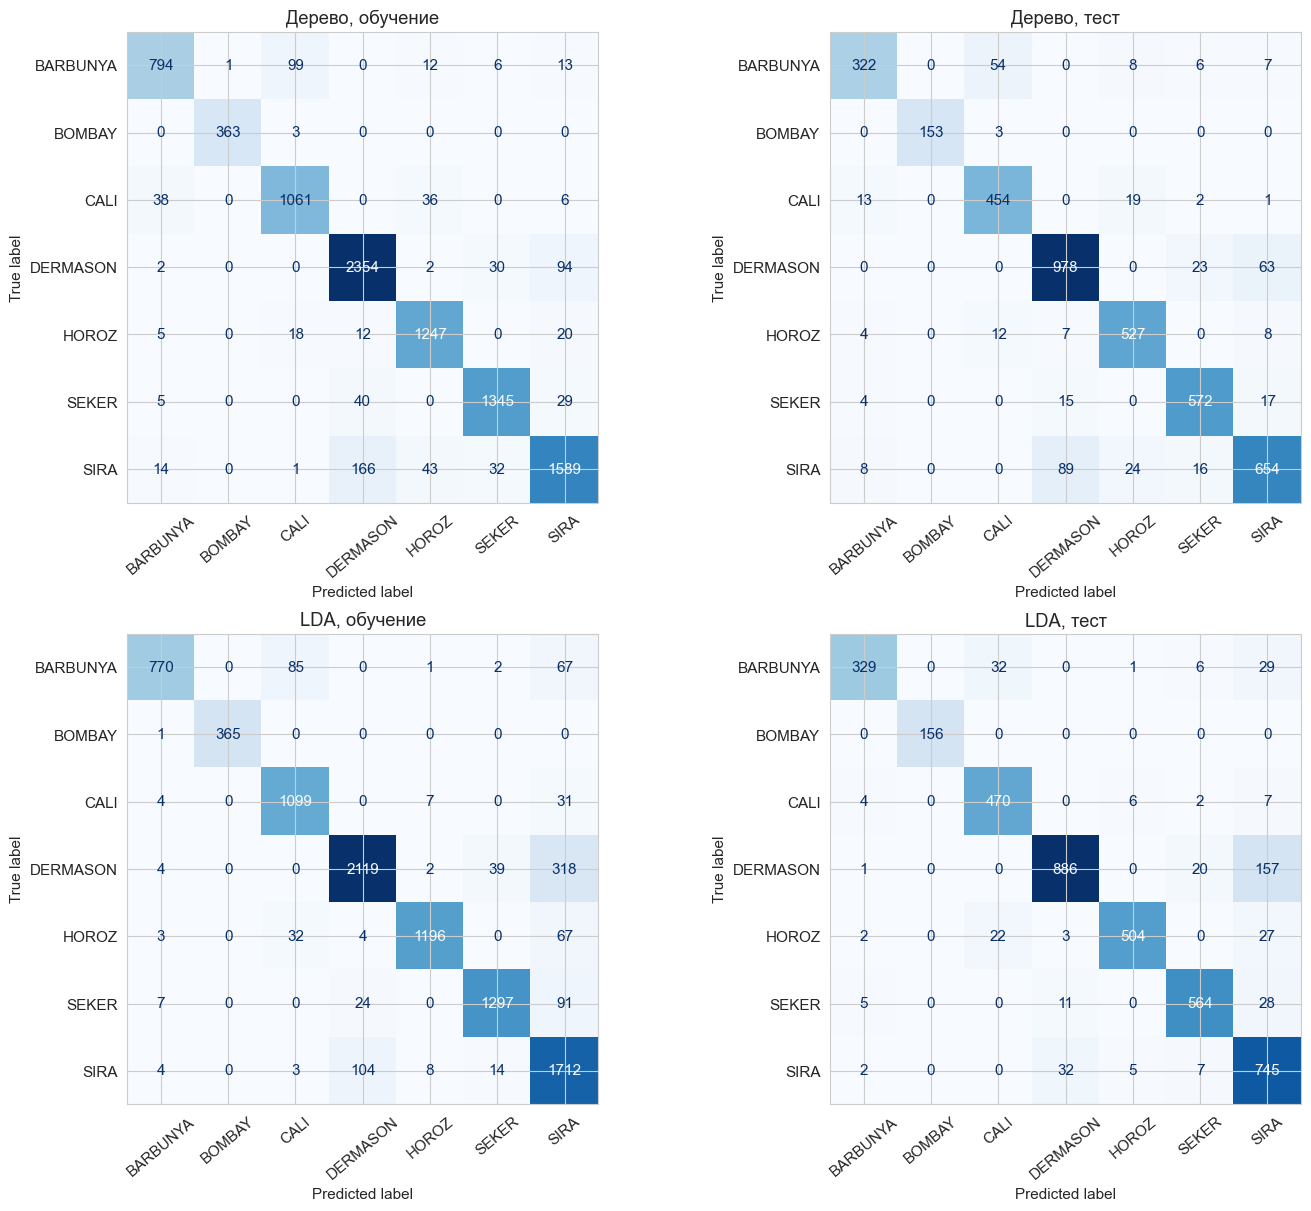

Тестовые матрицы, пять самых частых ошибок:
Дерево, тест: верно 3660 из 4063.
  SIRA → DERMASON: 89
  DERMASON → SIRA: 63
  BARBUNYA → CALI: 54
  SIRA → HOROZ: 24
  DERMASON → SEKER: 23
  ниже всего полнота у BARBUNYA: 0.811.
LDA, тест: верно 3654 из 4063.
  DERMASON → SIRA: 157
  SIRA → DERMASON: 32
  BARBUNYA → CALI: 32
  BARBUNYA → SIRA: 29
  SEKER → SIRA: 28
  ниже всего полнота у BARBUNYA: 0.829.
Отчёт по сортам, тест, дерево:
              precision    recall  f1-score   support

    BARBUNYA      0.917     0.811     0.861       397
      BOMBAY      1.000     0.981     0.990       156
        CALI      0.868     0.928     0.897       489
    DERMASON      0.898     0.919     0.908      1064
       HOROZ      0.912     0.944     0.928       558
       SEKER      0.924     0.941     0.932       608
        SIRA      0.872     0.827     0.849       791

    accuracy                          0.901      4063
   macro avg      0.913     0.907     0.909      4063
weighted avg      0.90

,Дерево,LDA
сорт,,
BARBUNYA,0.978,0.993
BOMBAY,1.000,1.000
CALI,0.980,0.996
DERMASON,0.983,0.990
HOROZ,0.985,0.996
SEKER,0.990,0.992
SIRA,0.966,0.980


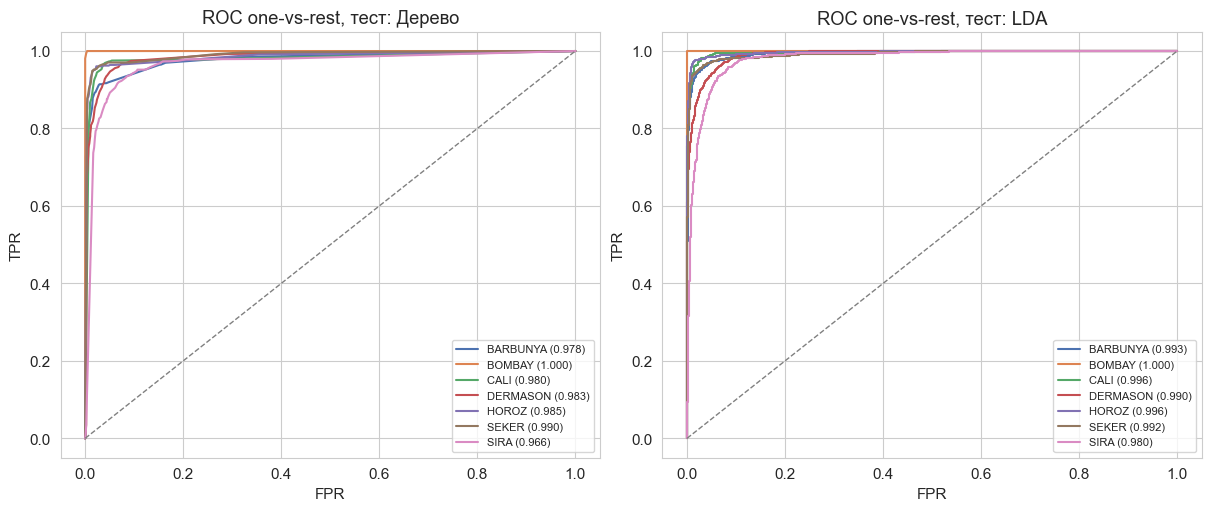

Стратифицированная 5-fold кросс-валидация на всей выборке после удаления дубликатов. Это проверка устойчивости сравнения, отложенный тест выше остаётся основной оценкой. Scaler LDA заново учится внутри каждого фолда.


,модель,accuracy,F1_macro,AUC_macro
0,Дерево,0.909 ± 0.006,0.921 ± 0.006,0.988 ± 0.002
1,LDA,0.901 ± 0.008,0.918 ± 0.008,0.993 ± 0.001


На отложенном тесте выше macro-F1 у модели «LDA»: дерево 0.909, LDA 0.916. Обе модели отделяют крупные и вытянутые зёрна уверенно; ошибки собираются между близкими по размеру сортами, это те же накрывающие друг друга облака, что на диаграммах рассеяния.


In [11]:
def aligned_proba(model, X, labels):
    proba = model.predict_proba(X)
    index = [list(model.classes_).index(label) for label in labels]
    return proba[:, index]


def calc_metrics(y_true, y_pred, y_proba):
    out = {"accuracy": float(accuracy_score(y_true, y_pred))}
    for avg in ("macro", "micro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=avg, zero_division=0, labels=LABELS,
        )
        out[f"precision_{avg}"] = float(precision)
        out[f"recall_{avg}"] = float(recall)
        out[f"f1_{avg}"] = float(f1)
    out["auc_macro"] = float(roc_auc_score(
        y_true, y_proba, multi_class="ovr", average="macro", labels=LABELS,
    ))
    out["auc_weighted"] = float(roc_auc_score(
        y_true, y_proba, multi_class="ovr", average="weighted", labels=LABELS,
    ))
    return out


def evaluate(name, model, columns=None):
    cols = list(X_train.columns if columns is None else columns)
    block = {}
    for split, Xs, ys in (("train", X_train, y_train), ("test", X_test, y_test)):
        pred = model.predict(Xs[cols])
        proba = aligned_proba(model, Xs[cols], LABELS)
        block[split] = calc_metrics(ys, pred, proba)
    METRICS[name] = block
    return block


def metrics_table():
    rows = []
    split_name = {"train": "обучение", "test": "тест"}
    for name, block in METRICS.items():
        for split in ("train", "test"):
            m = block[split]
            rows.append({
                "модель": name,
                "выборка": split_name[split],
                "accuracy": m["accuracy"],
                "precision_macro": m["precision_macro"],
                "recall_macro": m["recall_macro"],
                "F1_macro": m["f1_macro"],
                "F1_micro": m["f1_micro"],
                "F1_weighted": m["f1_weighted"],
                "AUC_macro": m["auc_macro"],
                "AUC_weighted": m["auc_weighted"],
            })
    return pd.DataFrame(rows)


def describe_cm(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    correct = int(np.trace(cm))
    total = int(cm.sum())
    print(f"{name}: верно {correct} из {total}.")
    pairs = []
    for i, actual in enumerate(LABELS):
        for j, predicted in enumerate(LABELS):
            if i != j and cm[i, j] > 0:
                pairs.append((int(cm[i, j]), actual, predicted))
    pairs.sort(reverse=True)
    for count, actual, predicted in pairs[:5]:
        print(f"  {actual} → {predicted}: {count}")
    recalls = recall_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    recall_s = pd.Series(recalls, index=LABELS)
    print(f"  ниже всего полнота у {recall_s.idxmin()}: {recall_s.min():.3f}.")
    return cm


METRICS = {}
evaluate("Дерево", tree_clf)
evaluate("LDA", lda_pipe)
print(
    "Для однометочной задачи micro-F1 совпадает с accuracy: каждый объект даёт одну верную или неверную метку. "
    "Разницу сортов показывает macro-F1."
)
display(metrics_table().round(3))

for name in ("Дерево", "LDA"):
    train_m = METRICS[name]["train"]
    test_m = METRICS[name]["test"]
    gap = train_m["accuracy"] - test_m["accuracy"]
    print(
        f"{name}: accuracy обучение {train_m['accuracy']:.3f}, тест {test_m['accuracy']:.3f}, "
        f"{gap_words(gap)} ({gap:+.3f}). "
        f"F1-macro тест {test_m['f1_macro']:.3f}, "
        f"AUC-macro тест {test_m['auc_macro']:.3f}."
    )

fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
panels = (
    (axes[0, 0], tree_clf, X_train, y_train, "Дерево, обучение"),
    (axes[0, 1], tree_clf, X_test, y_test, "Дерево, тест"),
    (axes[1, 0], lda_pipe, X_train, y_train, "LDA, обучение"),
    (axes[1, 1], lda_pipe, X_test, y_test, "LDA, тест"),
)
for ax, model, Xs, ys, title in panels:
    ConfusionMatrixDisplay.from_predictions(
        ys, model.predict(Xs), labels=LABELS, display_labels=LABELS,
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=40)
plt.show()

print("Тестовые матрицы, пять самых частых ошибок:")
describe_cm("Дерево, тест", y_test, tree_clf.predict(X_test))
describe_cm("LDA, тест", y_test, lda_pipe.predict(X_test))

print("Отчёт по сортам, тест, дерево:")
print(classification_report(
    y_test, tree_clf.predict(X_test), labels=LABELS, target_names=LABELS, digits=3, zero_division=0,
))
print("Отчёт по сортам, тест, LDA:")
print(classification_report(
    y_test, lda_pipe.predict(X_test), labels=LABELS, target_names=LABELS, digits=3, zero_division=0,
))

auc_rows = {"сорт": LABELS}
for name, model in (("Дерево", tree_clf), ("LDA", lda_pipe)):
    proba = aligned_proba(model, X_test, LABELS)
    y_bin = label_binarize(y_test, classes=LABELS)
    auc_rows[name] = [roc_auc_score(y_bin[:, i], proba[:, i]) for i in range(len(LABELS))]
auc_tbl = pd.DataFrame(auc_rows).set_index("сорт")
print("AUC one-vs-rest по сортам, тест:")
display(auc_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, model, title in ((axes[0], tree_clf, "Дерево"), (axes[1], lda_pipe, "LDA")):
    proba = aligned_proba(model, X_test, LABELS)
    y_bin = label_binarize(y_test, classes=LABELS)
    for i, cls in enumerate(LABELS):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        auc_i = roc_auc_score(y_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, color=PALETTE[cls], label=f"{cls} ({auc_i:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.set_title(f"ROC one-vs-rest, тест: {title}")
    ax.legend(fontsize=8)
plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "auc": "roc_auc_ovr"}
CV_SUMMARY = {}
print(
    "Стратифицированная 5-fold кросс-валидация на всей выборке после удаления дубликатов. "
    "Это проверка устойчивости сравнения, отложенный тест выше остаётся основной оценкой. "
    "Scaler LDA заново учится внутри каждого фолда."
)
cv_rows = []
for name, estimator in (("Дерево", make_tree()), ("LDA", make_lda())):
    result = cross_validate(
        estimator, X_model, y_model, cv=cv, scoring=scoring, n_jobs=1, return_train_score=False,
    )
    CV_SUMMARY[name] = {
        "accuracy": (float(result["test_accuracy"].mean()), float(result["test_accuracy"].std())),
        "f1_macro": (float(result["test_f1_macro"].mean()), float(result["test_f1_macro"].std())),
        "auc": (float(result["test_auc"].mean()), float(result["test_auc"].std())),
    }
    cv_rows.append({
        "модель": name,
        "accuracy": f"{result['test_accuracy'].mean():.3f} ± {result['test_accuracy'].std():.3f}",
        "F1_macro": f"{result['test_f1_macro'].mean():.3f} ± {result['test_f1_macro'].std():.3f}",
        "AUC_macro": f"{result['test_auc'].mean():.3f} ± {result['test_auc'].std():.3f}",
    })
display(pd.DataFrame(cv_rows))

tree_f1 = METRICS["Дерево"]["test"]["f1_macro"]
lda_f1 = METRICS["LDA"]["test"]["f1_macro"]
leader = "LDA" if lda_f1 >= tree_f1 else "Дерево"
print(
    f"На отложенном тесте выше macro-F1 у модели «{leader}»: "
    f"дерево {tree_f1:.3f}, LDA {lda_f1:.3f}. "
    "Обе модели отделяют крупные и вытянутые зёрна уверенно; ошибки собираются между близкими по размеру сортами, "
    "это те же накрывающие друг друга облака, что на диаграммах рассеяния."
)

## 9. Значимость признаков

У дерева значимость — нормированное убывание Джини по всем ветвлениям, в сумме 1. Признак с нулём ни разу не выбран порогом. У LDA — средний модуль стандартизованного коэффициента по сортам. Из-за пар с высокой корреляцией большой коэффициент сам по себе не доказывает самостоятельный вклад: два почти одинаковых размера делят один сигнал.

Для решения, какие признаки слабые, берём permutation importance LDA на **обучении**: во сколько раз падает macro-F1, если перемешать столбец. Перестановки не смотрят на тест, так что отбор в пункте 11 не подгоняется под отложенную ошибку.

,дерево,LDA |β|
ShapeFactor1,0.2549,19.0823
Compactness,0.2545,38.6327
MajorAxisLength,0.2021,170.0838
Perimeter,0.1625,53.3485
roundness,0.0691,7.2773
MinorAxisLength,0.0289,106.0380
ShapeFactor4,0.0123,3.2429
EquivDiameter,0.0081,320.3180
Solidity,0.0040,0.9847
Extent,0.0017,0.3055


Согласованность рангов дерева и |β| LDA: Spearman ρ = 0.297, p = 3.0297e-01.
Дерево использует: ShapeFactor1 (0.255), Compactness (0.254), MajorAxisLength (0.202), Perimeter (0.162), roundness (0.069), MinorAxisLength (0.029), ShapeFactor4 (0.012), EquivDiameter (0.008), Solidity (0.004), Extent (0.002), ShapeFactor2 (0.001), AspectRation (0.001), ConvexArea (0.000), Eccentricity (0.000)
Нулевой важности в дереве нет: каждый признак рабочего набора хотя бы раз участвует в убывании Джини.


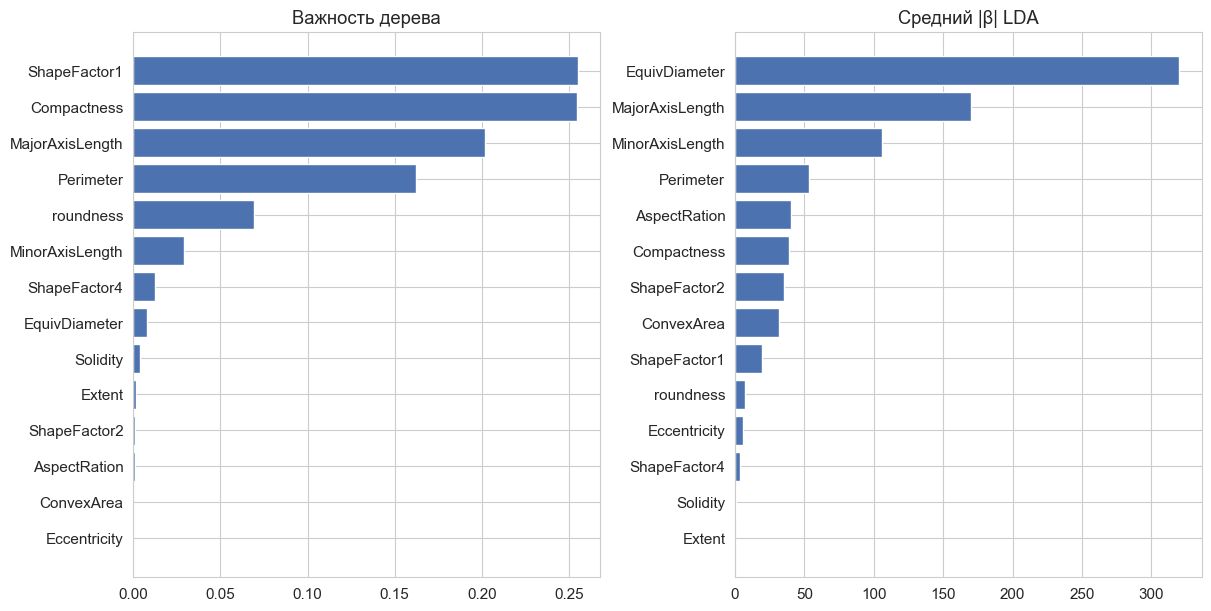

,importance,std
EquivDiameter,0.8472,0.0026
MajorAxisLength,0.7087,0.0037
Compactness,0.6215,0.0051
MinorAxisLength,0.5864,0.0046
AspectRation,0.4879,0.0040
Perimeter,0.4547,0.0047
ConvexArea,0.4221,0.0056
ShapeFactor2,0.3995,0.0040
ShapeFactor1,0.3440,0.0039
Eccentricity,0.2142,0.0031


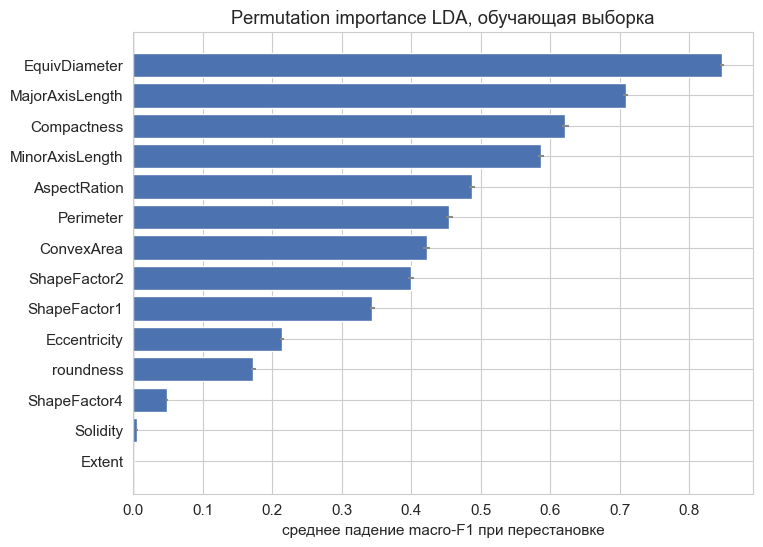

In [12]:
tree_imp = pd.Series(tree_clf.feature_importances_, index=X_train.columns)
lda_abs = pd.Series(np.abs(lda.coef_).mean(axis=0), index=X_train.columns)
rho_imp, rho_imp_p = spearmanr(tree_imp, lda_abs.loc[tree_imp.index])

imp_tbl = pd.DataFrame({
    "дерево": tree_imp,
    "LDA |β|": lda_abs,
}).sort_values("дерево", ascending=False)
display(imp_tbl.round(4))
print(f"Согласованность рангов дерева и |β| LDA: Spearman ρ = {rho_imp:.3f}, p = {fmt_p(rho_imp_p)}.")
zeros = tree_imp[tree_imp <= 1e-12].index.tolist()
used = tree_imp[tree_imp > 1e-12].sort_values(ascending=False)
print("Дерево использует:", ", ".join(f"{name} ({value:.3f})" for name, value in used.items()))
if zeros:
    print("Важность дерева равна 0:", ", ".join(zeros))
else:
    print("Нулевой важности в дереве нет: каждый признак рабочего набора хотя бы раз участвует в убывании Джини.")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, series, title in (
    (axes[0], tree_imp.sort_values(), "Важность дерева"),
    (axes[1], lda_abs.sort_values(), "Средний |β| LDA"),
):
    ax.barh(series.index, series.to_numpy(), color="#4C72B0")
    ax.set_title(title)
plt.show()

perm = permutation_importance(
    lda_pipe, X_train, y_train,
    scoring="f1_macro", n_repeats=20, random_state=42, n_jobs=1,
)
perm_mean = pd.Series(perm.importances_mean, index=X_train.columns)
perm_std = pd.Series(perm.importances_std, index=X_train.columns)
perm_tbl = pd.DataFrame({"importance": perm_mean, "std": perm_std}).sort_values("importance", ascending=False)
display(perm_tbl.round(4))

order = perm_mean.sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(order.index, order.to_numpy(), xerr=perm_std.loc[order.index], color="#4C72B0", ecolor="#888888")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("среднее падение macro-F1 при перестановке")
ax.set_title("Permutation importance LDA, обучающая выборка")
plt.show()

## 10. Влияние параметров дерева

Меняется один метод — дерево. Остальные настройки держатся на значениях пункта 7: при переборе глубины лист равен 20 и критерий Джини; при переборе листа глубина равна 8; Джини сравнивается с энтропией при глубине 8 и листе 20. Кривые ниже показывают чувствительность. Основная модель пункта 7 из-за этого перебора не подменяется: тестовая выборка уже использована для отчёта, выбирать по ней новую глубину и снова называть ту же цифру оценкой качества было бы подгонкой.

,label,train_acc,test_acc,train_f1,test_f1,nodes
0,1,0.410,0.403,0.163,0.160,3
1,2,0.655,0.646,0.455,0.449,7
2,3,0.778,0.769,0.600,0.593,15
3,4,0.828,0.813,0.761,0.749,31
4,5,0.892,0.875,0.893,0.878,57
5,6,0.910,0.890,0.916,0.898,89
6,8,0.923,0.901,0.930,0.909,183
7,10,0.930,0.904,0.939,0.914,237
8,12,0.930,0.904,0.939,0.914,257
9,без ограничения,0.930,0.904,0.939,0.914,289


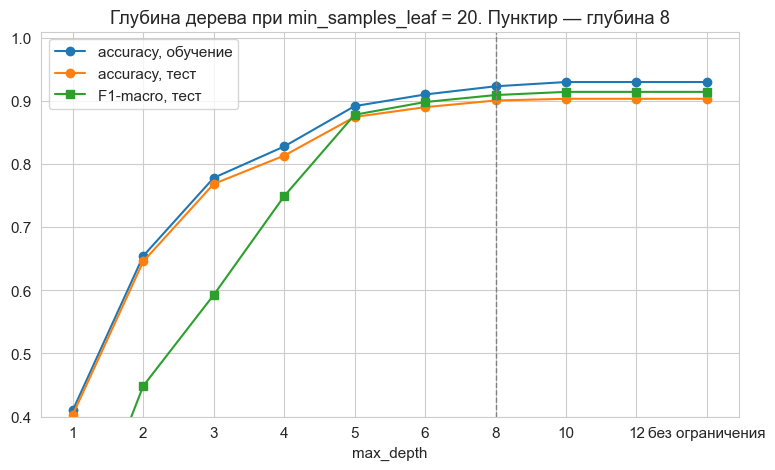

,min_samples_leaf,train_acc,test_acc,train_f1,test_f1
0,1,0.940,0.901,0.945,0.912
1,5,0.935,0.901,0.939,0.910
2,20,0.923,0.901,0.930,0.909
3,50,0.915,0.893,0.922,0.904
4,100,0.898,0.884,0.905,0.893
5,200,0.884,0.876,0.894,0.886


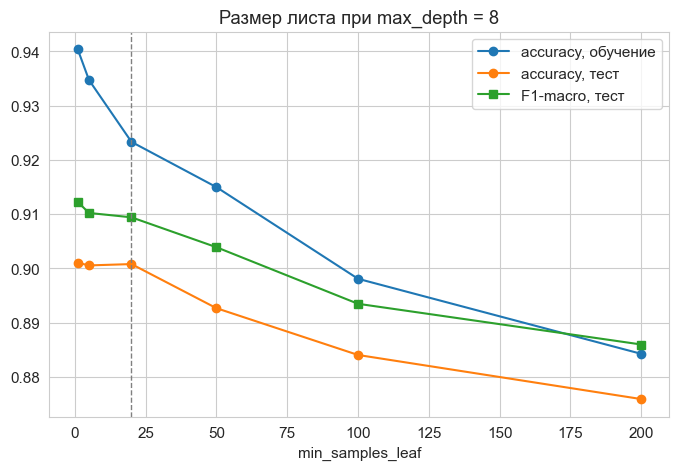

,criterion,train_acc,test_acc,train_f1,test_f1
0,gini,0.923,0.901,0.930,0.909
1,entropy,0.927,0.906,0.938,0.920


При глубине 8 macro-F1 на тесте 0.909. Максимум на этой кривой — 0.914 при глубине «10», прибавка +0.005.
Глубина 8 стоит у плато: дальнейшее углубление почти не меняет тест, лист не пускает дерево запоминать отдельные зёрна.
Глубина 3 даёт macro-F1 на тесте 0.593 против 0.909 у глубины 8: короткого дерева хватает только на грубое разделение по размеру.
Лист 1: accuracy обучение 0.940, тест 0.901. Лист 20: обучение 0.923, тест 0.901.
Джини и энтропия, macro-F1 на тесте: 0.909 и 0.920, разница +0.010.
Дерево отчёта остаётся с индексом Джини: он записан в параметрах пункта 7 и виден в каждом узле. Переход от глубины 3 к глубине 8 даёт куда больший прирост macro-F1 (0.593 → 0.909), чем смена критерия.


In [13]:
depth_rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    clf = make_tree(max_depth=depth)
    clf.fit(X_train, y_train)
    pred_tr = clf.predict(X_train)
    pred_te = clf.predict(X_test)
    depth_rows.append({
        "label": "без ограничения" if depth is None else str(depth),
        "depth_num": 99 if depth is None else depth,
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "train_f1": f1_score(y_train, pred_tr, average="macro", labels=LABELS),
        "test_f1": f1_score(y_test, pred_te, average="macro", labels=LABELS),
        "nodes": int(clf.tree_.node_count),
    })
depth_tbl = pd.DataFrame(depth_rows)
display(depth_tbl.assign(
    train_acc=lambda t: t["train_acc"].round(3),
    test_acc=lambda t: t["test_acc"].round(3),
    train_f1=lambda t: t["train_f1"].round(3),
    test_f1=lambda t: t["test_f1"].round(3),
).drop(columns=["depth_num"]))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(depth_tbl))
ax.plot(x, depth_tbl["train_acc"], marker="o", label="accuracy, обучение")
ax.plot(x, depth_tbl["test_acc"], marker="o", label="accuracy, тест")
ax.plot(x, depth_tbl["test_f1"], marker="s", label="F1-macro, тест")
ax.set_xticks(x)
ax.set_xticklabels(depth_tbl["label"])
chosen_pos = list(depth_tbl["label"]).index(str(TREE_DEPTH))
ax.axvline(chosen_pos, color="gray", ls="--", lw=1)
ax.set_xlabel("max_depth")
ax.set_ylim(0.4, 1.01)
ax.legend()
ax.set_title(f"Глубина дерева при min_samples_leaf = {TREE_LEAF}. Пунктир — глубина {TREE_DEPTH}")
plt.show()

leaf_rows = []
for leaf in [1, 5, 20, 50, 100, 200]:
    clf = make_tree(max_depth=TREE_DEPTH, min_samples_leaf=leaf)
    clf.fit(X_train, y_train)
    pred_tr = clf.predict(X_train)
    pred_te = clf.predict(X_test)
    leaf_rows.append({
        "min_samples_leaf": leaf,
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "train_f1": f1_score(y_train, pred_tr, average="macro", labels=LABELS),
        "test_f1": f1_score(y_test, pred_te, average="macro", labels=LABELS),
    })
leaf_tbl = pd.DataFrame(leaf_rows)
display(leaf_tbl.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(leaf_tbl["min_samples_leaf"], leaf_tbl["train_acc"], marker="o", label="accuracy, обучение")
ax.plot(leaf_tbl["min_samples_leaf"], leaf_tbl["test_acc"], marker="o", label="accuracy, тест")
ax.plot(leaf_tbl["min_samples_leaf"], leaf_tbl["test_f1"], marker="s", label="F1-macro, тест")
ax.axvline(TREE_LEAF, color="gray", ls="--", lw=1)
ax.set_xlabel("min_samples_leaf")
ax.set_title(f"Размер листа при max_depth = {TREE_DEPTH}")
ax.legend()
plt.show()

crit_rows = []
for criterion in ("gini", "entropy"):
    clf = make_tree(criterion=criterion)
    clf.fit(X_train, y_train)
    pred_tr = clf.predict(X_train)
    pred_te = clf.predict(X_test)
    crit_rows.append({
        "criterion": criterion,
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "train_f1": f1_score(y_train, pred_tr, average="macro", labels=LABELS),
        "test_f1": f1_score(y_test, pred_te, average="macro", labels=LABELS),
    })
crit_tbl = pd.DataFrame(crit_rows)
display(crit_tbl.round(3))

ref = depth_tbl.loc[depth_tbl["depth_num"] == TREE_DEPTH].iloc[0]
best = depth_tbl.sort_values(["test_f1", "depth_num"], ascending=[False, True]).iloc[0]
gain = float(best["test_f1"] - ref["test_f1"])
print(
    f"При глубине {TREE_DEPTH} macro-F1 на тесте {ref['test_f1']:.3f}. "
    f"Максимум на этой кривой — {best['test_f1']:.3f} при глубине «{best['label']}», прибавка {gain:+.3f}."
)
if gain < 0.01:
    print("Глубина 8 стоит у плато: дальнейшее углубление почти не меняет тест, лист не пускает дерево запоминать отдельные зёрна.")
else:
    print(
        "На этой же тестовой выборке более глубокое дерево даёт прибавку. "
        "Цифра максимума оптимистична, потому что глубина выбрана по тесту. В отчёте остаётся заранее взятая глубина 8."
    )
shallow = depth_tbl.loc[depth_tbl["depth_num"] == 3].iloc[0]
print(
    f"Глубина 3 даёт macro-F1 на тесте {shallow['test_f1']:.3f} против {ref['test_f1']:.3f} у глубины 8: "
    "короткого дерева хватает только на грубое разделение по размеру."
)
leaf_ref = leaf_tbl.loc[leaf_tbl["min_samples_leaf"] == TREE_LEAF].iloc[0]
leaf_one = leaf_tbl.loc[leaf_tbl["min_samples_leaf"] == 1].iloc[0]
print(
    f"Лист 1: accuracy обучение {leaf_one['train_acc']:.3f}, тест {leaf_one['test_acc']:.3f}. "
    f"Лист {TREE_LEAF}: обучение {leaf_ref['train_acc']:.3f}, тест {leaf_ref['test_acc']:.3f}."
)
gini_f1 = float(crit_tbl.loc[crit_tbl["criterion"] == "gini", "test_f1"].iloc[0])
ent_f1 = float(crit_tbl.loc[crit_tbl["criterion"] == "entropy", "test_f1"].iloc[0])
print(f"Джини и энтропия, macro-F1 на тесте: {gini_f1:.3f} и {ent_f1:.3f}, разница {ent_f1 - gini_f1:+.3f}.")
print(
    "Дерево отчёта остаётся с индексом Джини: он записан в параметрах пункта 7 и виден в каждом узле. "
    f"Переход от глубины 3 к глубине 8 даёт куда больший прирост macro-F1 "
    f"({shallow['test_f1']:.3f} → {ref['test_f1']:.3f}), чем смена критерия."
)

## 11. Удаление малозначимых признаков

Правило зафиксировано до просмотра тестовой ошибки. Малозначимый признак — тот, у которого средняя permutation importance LDA на обучении не выше нуля: перемешивание столбца не снижает macro-F1. Если таких признаков нет, берём три наименьших и помечаем шаг как проверку чувствительности. При данном объёме ANOVA не оставляет признаков с большим p-value, поэтому «слабый» здесь — слабый вклад в макро-F1, а не результат t-теста.

Проверка делается для LDA: коэффициент есть у каждого признака рабочего набора. Дерево на тех же столбцах пересчитывается рядом, чтобы было видно, пользовалось ли оно этими признаками. Оба пересчёта идут на том же разбиении.

In [14]:
sensitivity = False
weak_features = perm_mean[perm_mean <= 0].index.tolist()
if not weak_features:
    weak_features = perm_mean.nsmallest(3).index.tolist()
    sensitivity = True
    print(
        "Средняя permutation importance на обучении положительна у всех признаков рабочего набора: "
        "перестановка каждого снижает macro-F1."
    )
    print(
        "Дальше проверка чувствительности, не отбор по тесту. Убираем три признака с наименьшей importance: "
        + ", ".join(weak_features)
    )
else:
    print("Малозначимые признаки, importance ≤ 0:", ", ".join(weak_features))

keep = [c for c in X_train.columns if c not in set(weak_features)]
print(f"В пересчитанной модели признаков {len(keep)}:", ", ".join(keep))

lda_reduced = make_lda()
lda_reduced.fit(X_train[keep], y_train)
tree_reduced = make_tree()
tree_reduced.fit(X_train[keep], y_train)
evaluate("LDA без слабых", lda_reduced, keep)
evaluate("Дерево без слабых", tree_reduced, keep)
display(metrics_table().round(3))


def recall_frame(model, columns, title):
    pred = model.predict(X_test[columns])
    values = recall_score(y_test, pred, labels=LABELS, average=None, zero_division=0)
    return pd.Series(values, index=LABELS, name=title)


recall_cmp = pd.concat([
    recall_frame(lda_pipe, list(X_train.columns), "LDA"),
    recall_frame(lda_reduced, keep, "LDA без слабых"),
    recall_frame(tree_clf, list(X_train.columns), "Дерево"),
    recall_frame(tree_reduced, keep, "Дерево без слабых"),
], axis=1)
print("Полнота по сортам на тесте:")
display(recall_cmp.round(3))

for full_name, reduced_name in (("LDA", "LDA без слабых"), ("Дерево", "Дерево без слабых")):
    before = METRICS[full_name]["test"]
    after = METRICS[reduced_name]["test"]
    d_acc = after["accuracy"] - before["accuracy"]
    d_f1 = after["f1_macro"] - before["f1_macro"]
    d_auc = after["auc_macro"] - before["auc_macro"]
    print(
        f"{reduced_name}, тест: Δaccuracy = {d_acc:+.3f}, ΔF1-macro = {d_f1:+.3f}, ΔAUC-macro = {d_auc:+.3f}."
    )

used_by_tree = set(tree_imp[tree_imp > 1e-12].index)
removed = set(weak_features)
if removed.isdisjoint(used_by_tree):
    print("Удалённые признаки не входят в ветвления дерева, поэтому его метрики совпадают с исходными.")
else:
    print("Часть удалённых признаков дерево использовало:", ", ".join(sorted(removed & used_by_tree)))

d_acc_lda = METRICS["LDA без слабых"]["test"]["accuracy"] - METRICS["LDA"]["test"]["accuracy"]
if abs(d_acc_lda) < 0.005:
    print(
        "У LDA сдвиг accuracy меньше 0.005. При n теста около 4 тысяч это уровень шума одной выборки: "
        "убранные признаки почти не добавляли разделения сверх размера и формы, которые в модели остались."
    )
elif d_acc_lda < 0:
    print("Accuracy LDA на тесте снизилась: убранные признаки несли часть линейного сигнала, малый ранг не значит нулевой вклад.")
else:
    print("Accuracy LDA на тесте выросла: убранные признаки мешали линейному разделителю.")

Средняя permutation importance на обучении положительна у всех признаков рабочего набора: перестановка каждого снижает macro-F1.
Дальше проверка чувствительности, не отбор по тесту. Убираем три признака с наименьшей importance: Extent, Solidity, ShapeFactor4
В пересчитанной модели признаков 11: Perimeter, MajorAxisLength, MinorAxisLength, AspectRation, Eccentricity, ConvexArea, EquivDiameter, roundness, Compactness, ShapeFactor1, ShapeFactor2


,модель,выборка,accuracy,precision_macro,recall_macro,F1_macro,F1_micro,F1_weighted,AUC_macro,AUC_weighted
0,Дерево,обучение,0.923,0.932,0.928,0.930,0.923,0.923,0.994,0.993
1,Дерево,тест,0.901,0.913,0.907,0.909,0.901,0.900,0.983,0.981
2,LDA,обучение,0.903,0.930,0.915,0.920,0.903,0.905,0.993,0.991
3,LDA,тест,0.899,0.925,0.914,0.916,0.899,0.901,0.993,0.991
4,LDA без слабых,обучение,0.901,0.928,0.913,0.918,0.901,0.903,0.993,0.991
5,LDA без слабых,тест,0.899,0.924,0.912,0.915,0.899,0.900,0.992,0.990
6,Дерево без слабых,обучение,0.923,0.932,0.928,0.929,0.923,0.923,0.994,0.993
7,Дерево без слабых,тест,0.896,0.910,0.904,0.906,0.896,0.895,0.984,0.982


Полнота по сортам на тесте:


,LDA,LDA без слабых,Дерево,Дерево без слабых
BARBUNYA,0.829,0.816,0.811,0.793
BOMBAY,1.000,1.000,0.981,0.981
CALI,0.961,0.957,0.928,0.935
DERMASON,0.833,0.836,0.919,0.907
HOROZ,0.903,0.901,0.944,0.944
SEKER,0.928,0.929,0.941,0.949
SIRA,0.942,0.943,0.827,0.818


LDA без слабых, тест: Δaccuracy = -0.000, ΔF1-macro = -0.002, ΔAUC-macro = -0.000.
Дерево без слабых, тест: Δaccuracy = -0.005, ΔF1-macro = -0.004, ΔAUC-macro = +0.001.
Часть удалённых признаков дерево использовало: Extent, ShapeFactor4, Solidity
У LDA сдвиг accuracy меньше 0.005. При n теста около 4 тысяч это уровень шума одной выборки: убранные признаки почти не добавляли разделения сверх размера и формы, которые в модели остались.


## Сравнение и вывод

Числа ниже собраны из одной и той же стратифицированной выборки 70/30. Кросс-валидация из пункта 8 проверяет, что сравнение дерева и LDA не держится на одном разбиении.

,модель,выборка,accuracy,precision_macro,recall_macro,F1_macro,F1_micro,F1_weighted,AUC_macro,AUC_weighted
0,Дерево,обучение,0.923,0.932,0.928,0.930,0.923,0.923,0.994,0.993
1,Дерево,тест,0.901,0.913,0.907,0.909,0.901,0.900,0.983,0.981
2,LDA,обучение,0.903,0.930,0.915,0.920,0.903,0.905,0.993,0.991
3,LDA,тест,0.899,0.925,0.914,0.916,0.899,0.901,0.993,0.991
4,LDA без слабых,обучение,0.901,0.928,0.913,0.918,0.901,0.903,0.993,0.991
5,LDA без слабых,тест,0.899,0.924,0.912,0.915,0.899,0.900,0.992,0.990
6,Дерево без слабых,обучение,0.923,0.932,0.928,0.929,0.923,0.923,0.994,0.993
7,Дерево без слабых,тест,0.896,0.910,0.904,0.906,0.896,0.895,0.984,0.982


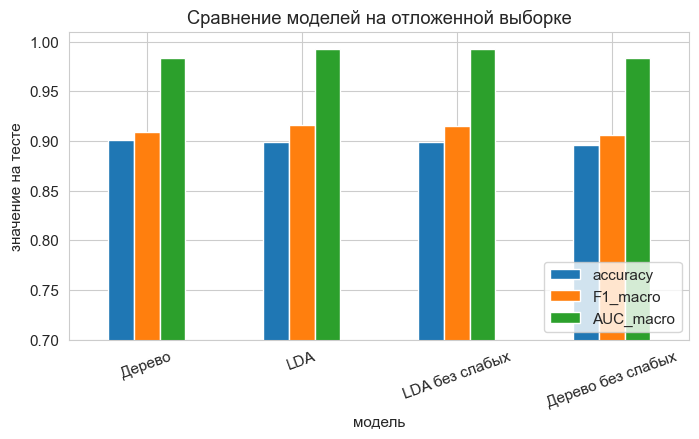

LDA на тесте: accuracy 0.899, macro-F1 0.916, macro-AUC 0.993.
Дерево на тесте: accuracy 0.901, macro-F1 0.909, macro-AUC 0.983.
Разрыв accuracy обучение−тест: LDA +0.003 (разрыв маленький), дерево +0.023 (небольшой разрыв).
Кросс-валидация, macro-F1: LDA 0.918 ± 0.008, дерево 0.921 ± 0.006.
По macro-F1 модели близки. LDA собирает размер и форму в одну линейную функцию, глубокое дерево нарезает то же пространство порогами. Ошибки обоих сидят между сортами с похожим контуром.
Глубина дерева. На кривой пункта 10 macro-F1 теста при глубине 8 равна 0.909, максимум кривой 0.914 (глубина «10»).
Выбранная глубина лежит на плато. Более глубокое дерево при листе 20 почти не поднимает тест.
Критерий: Джини 0.909, энтропия 0.920 по macro-F1 на тесте. Глубина с 3 до 8 поднимает macro-F1 с 0.593 до 0.909. Лист 1 даёт accuracy обучения 0.940 при тесте 0.901; лист 200 снижает тест до 0.876.
Слабые признаки по нижней тройке permutation importance: Extent, Solidity, ShapeFactor4.
Ещё до моделей как коп

In [15]:
display(metrics_table().round(3))

test_view = metrics_table()
test_view = test_view[test_view["выборка"] == "тест"].set_index("модель")
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = test_view[["accuracy", "F1_macro", "AUC_macro"]]
plot_df.plot(kind="bar", ax=ax, rot=20)
ax.set_ylim(0.7, 1.01)
ax.set_ylabel("значение на тесте")
ax.set_title("Сравнение моделей на отложенной выборке")
ax.legend(loc="lower right")
plt.show()

tree_te = METRICS["Дерево"]["test"]
lda_te = METRICS["LDA"]["test"]
tree_tr = METRICS["Дерево"]["train"]
lda_tr = METRICS["LDA"]["train"]
print(
    f"LDA на тесте: accuracy {lda_te['accuracy']:.3f}, macro-F1 {lda_te['f1_macro']:.3f}, "
    f"macro-AUC {lda_te['auc_macro']:.3f}."
)
print(
    f"Дерево на тесте: accuracy {tree_te['accuracy']:.3f}, macro-F1 {tree_te['f1_macro']:.3f}, "
    f"macro-AUC {tree_te['auc_macro']:.3f}."
)
print(
    f"Разрыв accuracy обучение−тест: LDA {lda_tr['accuracy'] - lda_te['accuracy']:+.3f} "
    f"({gap_words(lda_tr['accuracy'] - lda_te['accuracy'])}), "
    f"дерево {tree_tr['accuracy'] - tree_te['accuracy']:+.3f} "
    f"({gap_words(tree_tr['accuracy'] - tree_te['accuracy'])})."
)
cv_lda = CV_SUMMARY["LDA"]["f1_macro"]
cv_tree = CV_SUMMARY["Дерево"]["f1_macro"]
print(
    f"Кросс-валидация, macro-F1: LDA {cv_lda[0]:.3f} ± {cv_lda[1]:.3f}, "
    f"дерево {cv_tree[0]:.3f} ± {cv_tree[1]:.3f}."
)
if abs(lda_te["f1_macro"] - tree_te["f1_macro"]) < 0.02:
    print(
        "По macro-F1 модели близки. LDA собирает размер и форму в одну линейную функцию, "
        "глубокое дерево нарезает то же пространство порогами. Ошибки обоих сидят между сортами с похожим контуром."
    )
elif lda_te["f1_macro"] > tree_te["f1_macro"]:
    print(
        "LDA выше по macro-F1: сорта разъехались по средним, и линейная комбинация признаков это использует. "
        "Дерево приближает ту же границу прямоугольными порогами и на глубине 8 ещё не добирает тот же macro-F1."
    )
else:
    print(
        "Дерево выше по macro-F1: часть границ между близкими сортами не укладывается в общую линейную функцию LDA, "
        "и последовательные пороги их добирают."
    )

print(
    f"Глубина дерева. На кривой пункта 10 macro-F1 теста при глубине 8 равна {ref['test_f1']:.3f}, "
    f"максимум кривой {best['test_f1']:.3f} (глубина «{best['label']}»)."
)
if gain < 0.01:
    print("Выбранная глубина лежит на плато. Более глубокое дерево при листе 20 почти не поднимает тест.")
else:
    print("Подъём после глубины 8 есть, но он прочитан по тому же тесту, поэтому основной моделью остаётся глубина 8.")
leaf_big = leaf_tbl.loc[leaf_tbl["min_samples_leaf"] == 200].iloc[0]
print(
    f"Критерий: Джини {gini_f1:.3f}, энтропия {ent_f1:.3f} по macro-F1 на тесте. "
    f"Глубина с 3 до 8 поднимает macro-F1 с {shallow['test_f1']:.3f} до {ref['test_f1']:.3f}. "
    f"Лист 1 даёт accuracy обучения {leaf_one['train_acc']:.3f} при тесте {leaf_one['test_acc']:.3f}; "
    f"лист 200 снижает тест до {leaf_big['test_acc']:.3f}."
)

removed_txt = ", ".join(weak_features)
if sensitivity:
    print(f"Слабые признаки по нижней тройке permutation importance: {removed_txt}.")
else:
    print(f"Признаки с permutation importance ≤ 0: {removed_txt}.")
if dropped_copies:
    copy_txt = ", ".join(feature for feature, _, _ in dropped_copies)
    print(f"Ещё до моделей как копии сняты: {copy_txt}.")
print(
    f"Удаление {removed_txt} меняет accuracy LDA на тесте на {d_acc_lda:+.3f}. "
    "В модели остаются размер и форма, и этого хватает для того же качества."
)

## Дополнительно: kNN, свёрточная сеть и трансформер

Три модели считаются на том же рабочем наборе и том же разбиении 70/30. Тест в подбор параметров не входит.

**kNN.** Сорт — метка ближайших зёрен в пространстве стандартизованных признаков. `StandardScaler` обязателен: площадь и форм-факторы иначе несопоставимы, и расстояние съест мелкие оси. Веса `distance`: ближнее зерно получает больший голос. Число соседей `k` выбирается по macro-F1 на стратифицированной 5-fold кросс-валидации внутри обучения.

**CNN.** Вектор признаков — короткая последовательность длины 14, один канал, не изображение зерна. Свёртка с ядром 3 смотрит три соседних измерения, поэтому признаки для сети упорядочены блоком размера, затем блоком формы. Структура:

- `Conv1d(1 → 32, kernel=3, padding=1)`, ReLU
- `Conv1d(32 → 64, kernel=3, padding=1)`, ReLU, Dropout 0.2
- усреднение по длине, `Linear(64 → 7)`

**Трансформер.** Каждый признак — токен. Скаляр проецируется в вектор размерности 32, к нему добавляется обучаемый позиционный вектор. Энкодер: 2 слоя, 4 головы, полносвязный блок 64, dropout 0.1. Дальше среднее по токенам и `Linear(32 → 7)`.

Обе сети: `CrossEntropyLoss` с весами, обратно пропорциональными доле сорта в обучении, Adam, `lr = 10^{-3}`, размер батча 256. Число эпох выбирается по macro-F1 на 15% обучения (ранняя остановка, терпение 5 эпох, не больше 30). Итоговая сеть заново учится на всём обучении это число эпох. `random_state` и seed равны 42.

Порядок признаков для CNN и трансформера: Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, EquivDiameter, AspectRation, Eccentricity, Extent, Solidity, roundness, Compactness, ShapeFactor1, ShapeFactor2, ShapeFactor4


,k,f1_mean,f1_std
3,15,0.937,0.003
4,25,0.937,0.003
1,5,0.936,0.004
2,11,0.936,0.003
5,41,0.935,0.003
0,3,0.931,0.003


k = 15: лучший средний macro-F1 на кросс-валидации обучения (0.937). При равенстве берётся меньшее k.


CNN: параметров 6791, эпох по валидации 29, macro-F1 валидации 0.918.
Трансформер: параметров 17831, эпох по валидации 14, macro-F1 валидации 0.932.


,epoch,train_loss,val_f1
0,1,1.8681,0.0161
1,2,1.6463,0.4962
2,3,1.3797,0.6607
3,4,1.1158,0.7605
4,5,0.8892,0.7869
5,6,0.7208,0.8012
6,7,0.6148,0.8100
7,8,0.5506,0.8274
8,9,0.5052,0.8241
9,10,0.4753,0.8416


,epoch,train_loss,val_f1
0,1,1.6730,0.4216
1,2,1.2242,0.6284
2,3,0.8263,0.8268
3,4,0.4949,0.8610
4,5,0.3584,0.8996
5,6,0.2853,0.9187
6,7,0.2490,0.9163
7,8,0.2356,0.9185
8,9,0.2230,0.9265
9,10,0.2113,0.9302


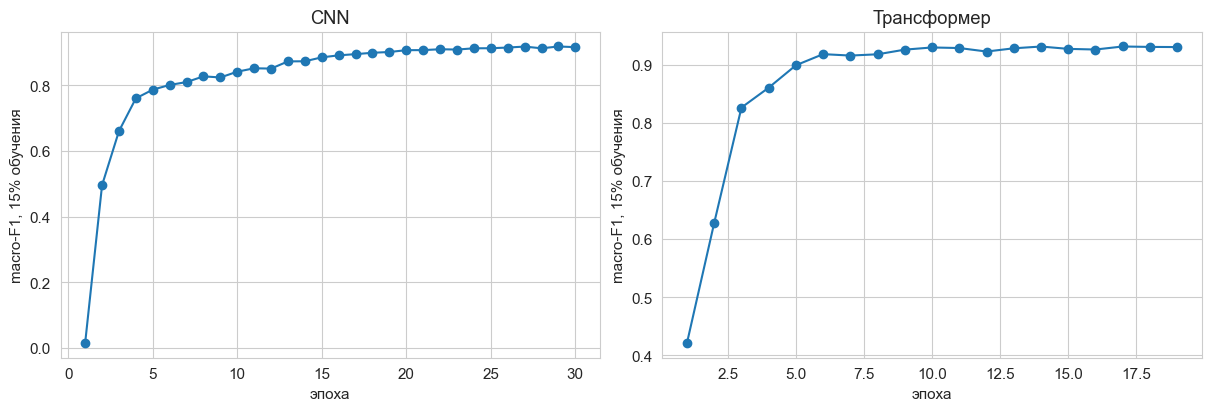

Метрики всех моделей, включая kNN, CNN и трансформер:


,модель,выборка,accuracy,precision_macro,recall_macro,F1_macro,F1_micro,F1_weighted,AUC_macro,AUC_weighted
0,Дерево,обучение,0.923,0.932,0.928,0.930,0.923,0.923,0.994,0.993
1,Дерево,тест,0.901,0.913,0.907,0.909,0.901,0.900,0.983,0.981
2,LDA,обучение,0.903,0.930,0.915,0.920,0.903,0.905,0.993,0.991
3,LDA,тест,0.899,0.925,0.914,0.916,0.899,0.901,0.993,0.991
4,LDA без слабых,обучение,0.901,0.928,0.913,0.918,0.901,0.903,0.993,0.991
5,LDA без слабых,тест,0.899,0.924,0.912,0.915,0.899,0.900,0.992,0.990
6,Дерево без слабых,обучение,0.923,0.932,0.928,0.929,0.923,0.923,0.994,0.993
7,Дерево без слабых,тест,0.896,0.910,0.904,0.906,0.896,0.895,0.984,0.982
8,kNN,обучение,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
9,kNN,тест,0.919,0.934,0.931,0.932,0.919,0.919,0.990,0.989


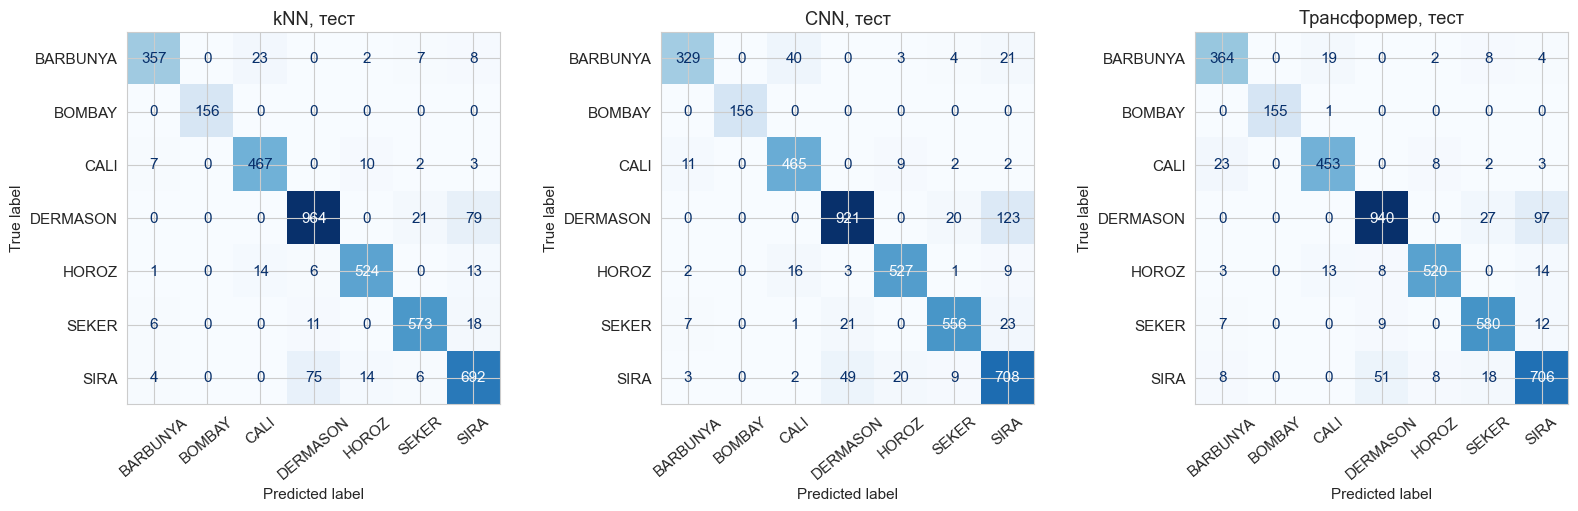

Полнота по сортам на тесте:


,kNN,CNN,Трансформер
BARBUNYA,0.899,0.829,0.917
BOMBAY,1.000,1.000,0.994
CALI,0.955,0.951,0.926
DERMASON,0.906,0.866,0.883
HOROZ,0.939,0.944,0.932
SEKER,0.942,0.914,0.954
SIRA,0.875,0.895,0.893


kNN: accuracy обучение 1.000, тест 0.919, на обучении точка является соседом самой себе, поэтому эта accuracy равна 1; качество kNN читается по тесту. F1-macro тест 0.932, AUC-macro тест 0.990.
CNN: accuracy обучение 0.908, тест 0.901, разрыв маленький (+0.006). F1-macro тест 0.915, AUC-macro тест 0.991.
Трансформер: accuracy обучение 0.926, тест 0.915, разрыв маленький (+0.011). F1-macro тест 0.927, AUC-macro тест 0.994.
Из трёх добавленных моделей выше всех macro-F1 на тесте у «kNN» (0.932). У LDA на том же тесте macro-F1 0.916.
«kNN» обходит LDA больше чем на 0.01 macro-F1: локальные сочетания признаков или соседство в пространстве зёрен добавляют разделение сверх линейных средних.


In [16]:
import torch
from torch import nn
from sklearn.neighbors import KNeighborsClassifier

torch.manual_seed(42)
label_to_i = {label: i for i, label in enumerate(LABELS)}
n_classes = len(LABELS)
neural_order = (
    [c for c in SIZE_FEATURES if c in X_train.columns]
    + [c for c in X_train.columns if c not in SIZE_FEATURES]
)
print("Порядок признаков для CNN и трансформера:", ", ".join(neural_order))

knn_rows = []
knn_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for k in (3, 5, 11, 15, 25, 41):
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="distance", metric="euclidean")),
    ])
    scores = cross_validate(
        candidate, X_train, y_train, cv=knn_cv, scoring="f1_macro", n_jobs=1,
    )["test_score"]
    knn_rows.append({"k": k, "f1_mean": float(scores.mean()), "f1_std": float(scores.std())})
knn_tbl = pd.DataFrame(knn_rows).sort_values(["f1_mean", "k"], ascending=[False, True])
display(knn_tbl.round(3))
best_k = int(knn_tbl.iloc[0]["k"])
print(
    f"k = {best_k}: лучший средний macro-F1 на кросс-валидации обучения "
    f"({knn_tbl.iloc[0]['f1_mean']:.3f}). При равенстве берётся меньшее k."
)
knn_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k, weights="distance", metric="euclidean")),
])
knn_clf.fit(X_train, y_train)
evaluate("kNN", knn_clf)


def class_weights(y_idx):
    counts = np.bincount(y_idx, minlength=n_classes).astype(np.float32)
    weights = counts.sum() / (n_classes * np.maximum(counts, 1.0))
    return torch.tensor(weights)


class BeanCNN(nn.Module):
    """1 канал × длина признаков. Два свёрточных слоя и линейная голова на 7 сортов."""

    def __init__(self, n_out):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout(0.2),
        )
        self.head = nn.Linear(64, n_out)

    def forward(self, x):
        hidden = self.conv(x.unsqueeze(1))
        return self.head(hidden.mean(dim=2))


class BeanTransformer(nn.Module):
    """Каждый признак — токен. Два слоя энкодера, затем среднее и линейная голова."""

    def __init__(self, n_features, n_out, d_model=32, nhead=4, nlayers=2, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(1, d_model)
        self.pos = nn.Parameter(torch.zeros(1, n_features, d_model))
        nn.init.normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=nlayers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, n_out)

    def forward(self, x):
        hidden = self.proj(x.unsqueeze(-1)) + self.pos
        hidden = self.encoder(hidden)
        return self.head(hidden.mean(dim=1))


class TabularNet:
    """Обёртка с predict / predict_proba в том же виде, что у моделей sklearn."""

    def __init__(self, net, scaler, feature_order, labels):
        self.net = net
        self.scaler = scaler
        self.feature_order = list(feature_order)
        self.classes_ = np.asarray(labels)
        self.net.eval()

    def predict_proba(self, X):
        matrix = np.asarray(X[self.feature_order], dtype=np.float32)
        scaled = self.scaler.transform(matrix).astype(np.float32)
        self.net.eval()
        with torch.no_grad():
            logits = self.net(torch.from_numpy(scaled))
            proba = torch.softmax(logits, dim=1).numpy()
        return proba

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def n_params(net):
    return sum(parameter.numel() for parameter in net.parameters() if parameter.requires_grad)


def run_epochs(net, x_tensor, y_tensor, loss_fn, optimizer, epochs):
    n_rows = x_tensor.shape[0]
    net.train()
    for _ in range(epochs):
        order = torch.randperm(n_rows)
        for start in range(0, n_rows, 256):
            batch = order[start:start + 256]
            optimizer.zero_grad()
            loss = loss_fn(net(x_tensor[batch]), y_tensor[batch])
            loss.backward()
            optimizer.step()


def select_epochs(make_net, x_fit, y_fit, x_val, y_val, epochs=30, patience=5, lr=1e-3):
    torch.manual_seed(42)
    net = make_net()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(y_fit))
    x_fit_t = torch.from_numpy(x_fit)
    y_fit_t = torch.from_numpy(y_fit.astype(np.int64))
    x_val_t = torch.from_numpy(x_val)
    best_f1 = -1.0
    best_epoch = 0
    wait = 0
    history = []
    n_rows = x_fit_t.shape[0]
    for epoch in range(1, epochs + 1):
        net.train()
        order = torch.randperm(n_rows)
        total = 0.0
        for start in range(0, n_rows, 256):
            batch = order[start:start + 256]
            optimizer.zero_grad()
            loss = loss_fn(net(x_fit_t[batch]), y_fit_t[batch])
            loss.backward()
            optimizer.step()
            total += float(loss.item()) * len(batch)
        net.eval()
        with torch.no_grad():
            val_pred = net(x_val_t).argmax(dim=1).numpy()
        val_f1 = float(f1_score(y_val, val_pred, average="macro", labels=list(range(n_classes))))
        history.append({"epoch": epoch, "train_loss": total / n_rows, "val_f1": val_f1})
        if val_f1 > best_f1 + 1e-4:
            best_f1 = val_f1
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best_epoch, best_f1, pd.DataFrame(history)


def fit_network(make_net, x_train_s, y_idx, epochs, lr=1e-3):
    torch.manual_seed(42)
    net = make_net()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(y_idx))
    run_epochs(
        net,
        torch.from_numpy(x_train_s),
        torch.from_numpy(y_idx.astype(np.int64)),
        loss_fn,
        optimizer,
        epochs,
    )
    net.eval()
    return net


X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train,
)
scaler_sel = StandardScaler().fit(X_fit[neural_order])
x_fit_s = scaler_sel.transform(X_fit[neural_order]).astype(np.float32)
x_val_s = scaler_sel.transform(X_val[neural_order]).astype(np.float32)
y_fit_idx = y_fit.map(label_to_i).to_numpy()
y_val_idx = y_val.map(label_to_i).to_numpy()
y_all_idx = y_train.map(label_to_i).to_numpy()
scaler_all = StandardScaler().fit(X_train[neural_order])
x_all_s = scaler_all.transform(X_train[neural_order]).astype(np.float32)

cnn_epoch, cnn_val_f1, cnn_hist = select_epochs(
    lambda: BeanCNN(n_classes), x_fit_s, y_fit_idx, x_val_s, y_val_idx,
)
tr_epoch, tr_val_f1, tr_hist = select_epochs(
    lambda: BeanTransformer(len(neural_order), n_classes), x_fit_s, y_fit_idx, x_val_s, y_val_idx,
)
print(f"CNN: параметров {n_params(BeanCNN(n_classes))}, эпох по валидации {cnn_epoch}, macro-F1 валидации {cnn_val_f1:.3f}.")
print(
    f"Трансформер: параметров {n_params(BeanTransformer(len(neural_order), n_classes))}, "
    f"эпох по валидации {tr_epoch}, macro-F1 валидации {tr_val_f1:.3f}."
)
display(cnn_hist.round(4))
display(tr_hist.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, hist, title in ((axes[0], cnn_hist, "CNN"), (axes[1], tr_hist, "Трансформер")):
    ax.plot(hist["epoch"], hist["val_f1"], marker="o")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("macro-F1, 15% обучения")
    ax.set_title(title)
plt.show()

cnn_net = fit_network(lambda: BeanCNN(n_classes), x_all_s, y_all_idx, cnn_epoch)
tr_net = fit_network(
    lambda: BeanTransformer(len(neural_order), n_classes), x_all_s, y_all_idx, tr_epoch,
)
cnn_clf = TabularNet(cnn_net, scaler_all, neural_order, LABELS)
tr_clf = TabularNet(tr_net, scaler_all, neural_order, LABELS)
evaluate("CNN", cnn_clf)
evaluate("Трансформер", tr_clf)

print("Метрики всех моделей, включая kNN, CNN и трансформер:")
display(metrics_table().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, name, model in (
    (axes[0], "kNN", knn_clf),
    (axes[1], "CNN", cnn_clf),
    (axes[2], "Трансформер", tr_clf),
):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), labels=LABELS, display_labels=LABELS,
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(f"{name}, тест")
    ax.tick_params(axis="x", labelrotation=40)
plt.show()

recall_extra = pd.concat([
    pd.Series(
        recall_score(y_test, model.predict(X_test), labels=LABELS, average=None, zero_division=0),
        index=LABELS, name=name,
    )
    for name, model in (("kNN", knn_clf), ("CNN", cnn_clf), ("Трансформер", tr_clf))
], axis=1)
print("Полнота по сортам на тесте:")
display(recall_extra.round(3))

extra = ["kNN", "CNN", "Трансформер"]
for name in extra:
    train_m = METRICS[name]["train"]
    test_m = METRICS[name]["test"]
    gap = train_m["accuracy"] - test_m["accuracy"]
    if name == "kNN":
        note = "на обучении точка является соседом самой себе, поэтому эта accuracy равна 1; качество kNN читается по тесту"
    else:
        note = f"{gap_words(gap)} ({gap:+.3f})"
    print(
        f"{name}: accuracy обучение {train_m['accuracy']:.3f}, тест {test_m['accuracy']:.3f}, "
        f"{note}. "
        f"F1-macro тест {test_m['f1_macro']:.3f}, AUC-macro тест {test_m['auc_macro']:.3f}."
    )

best_extra = max(extra, key=lambda name: METRICS[name]["test"]["f1_macro"])
lda_f1_test = METRICS["LDA"]["test"]["f1_macro"]
best_f1_test = METRICS[best_extra]["test"]["f1_macro"]
print(
    f"Из трёх добавленных моделей выше всех macro-F1 на тесте у «{best_extra}» ({best_f1_test:.3f}). "
    f"У LDA на том же тесте macro-F1 {lda_f1_test:.3f}."
)
if best_f1_test + 0.01 < lda_f1_test:
    print(
        "Линейная дискриминантная функция на этих 14 измерениях по-прежнему сильнее. "
        "Короткая последовательность признаков даёт свёртке и вниманию мало соседней структуры сверх того, "
        "что LDA собирает одной матрицей ковариаций."
    )
elif best_f1_test > lda_f1_test + 0.01:
    print(
        f"«{best_extra}» обходит LDA больше чем на 0.01 macro-F1: "
        "локальные сочетания признаков или соседство в пространстве зёрен добавляют разделение сверх линейных средних."
    )
else:
    print(
        "Разница с LDA укладывается в 0.01 macro-F1. "
        "На этой таблице kNN, свёртка и внимание читают ту же геометрию размера и формы."
    )